In [1]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=b43ec1f80e733af8ac92aecca6201da0f276d0c0d8a231a29b4877711904ba1a
  Stored in directory: /root/.cache/pip/wheels/05/bd/e2/0c0eecf3c26b6cdb231b5656d53905bddc8090d69619d57e6b
Successfully built grad-cam


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import cv2
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms, models
from torch.optim.lr_scheduler import ReduceLROnPlateau, StepLR

# TensorBoard
from torch.utils.tensorboard import SummaryWriter

# Grad-CAM
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Sklearn
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Settings
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using: {device}')

# Metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    cohen_kappa_score
)

import torch.nn.functional as F

SEED = 4747
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

2026-10-13 18:01:27.089388: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791914487.321844      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791914487.389446      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1791914487.965938      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791914487.965977      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791914487.965980      58 computation_placer.cc:177] computation placer alr

Using: cuda


2. Exploratory Data Analysis (EDA)

In [6]:

TRAIN_DIR = '/kaggle/input/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/train'
TEST_DIR = '/kaggle/input/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/test'
VAL_DIR = '/kaggle/input/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/val'

def analyze_dataset(data_dir):
    class_counts = {}
    total_images = 0
    image_sizes = []
    
    for class_name in os.listdir(data_dir):
        class_path = os.path.join(data_dir, class_name)
        if os.path.isdir(class_path):
            images = os.listdir(class_path)
            class_counts[class_name] = len(images)
            total_images += len(images)
            
            for img_name in images[:10]:
                img_path = os.path.join(class_path, img_name)
                try:
                    img = Image.open(img_path)
                    image_sizes.append(img.size)
                except:
                    pass
    
    return class_counts, total_images, image_sizes

# train, val, test
train_counts, train_total, train_sizes = analyze_dataset(TRAIN_DIR)
val_counts, val_total, val_sizes = analyze_dataset(VAL_DIR)
test_counts, test_total, test_sizes = analyze_dataset(TEST_DIR)

print("Datasets analysis")
print(f"\nTrain: {train_total} images")
print(f"Validation: {val_total} images")
print(f"Test: {test_total} images")
print(f"Total: {train_total + val_total + test_total} images\n")

Datasets analysis

Train: 5778 images
Validation: 826 images
Test: 1656 images
Total: 8260 images



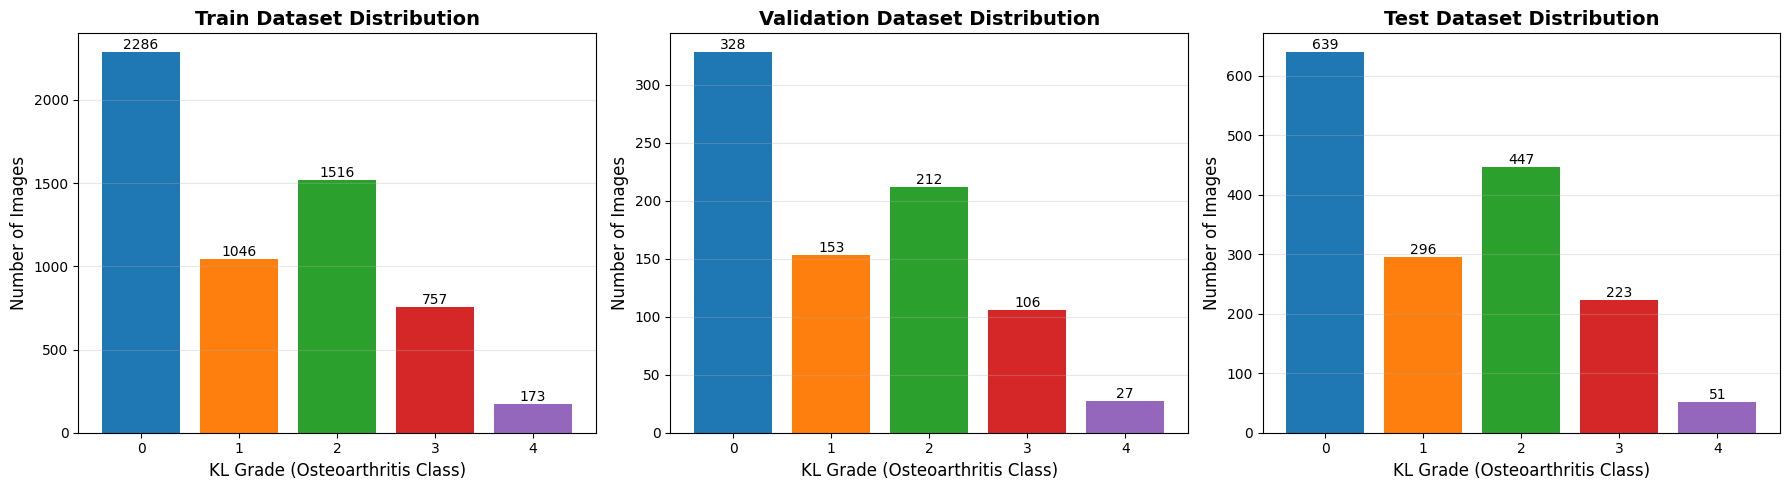


Class distribution in the training set:
Class 0: 2286 (39.6%)
Class 1: 1046 (18.1%)
Class 2: 1516 (26.2%)
Class 3: 757 (13.1%)
Class 4: 173 (3.0%)

Imbalance Ratio: 13.21
Significant class imbalance detected! Using WeightedRandomSampler or data augmentation is recommended.


In [7]:
# Visualize class distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

datasets_info = [
    ('Train', train_counts),
    ('Validation', val_counts),
    ('Test', test_counts)
]

for ax, (title, counts) in zip(axes, datasets_info):
    classes = sorted(counts.keys())
    values = [counts[c] for c in classes]
    
    bars = ax.bar(classes, values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'])
    ax.set_title(f'{title} Dataset Distribution', fontsize=14, fontweight='bold')
    ax.set_xlabel('KL Grade (Osteoarthritis Class)', fontsize=12)
    ax.set_ylabel('Number of Images', fontsize=12)
    ax.grid(axis='y', alpha=0.3)
    
    # Add value labels on top of bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height)}',
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Check for class imbalance
print("\nClass distribution in the training set:")
for class_name, count in sorted(train_counts.items()):
    percentage = (count / train_total) * 100
    print(f"Class {class_name}: {count} ({percentage:.1f}%)")

# Determine if balancing is necessary
max_count = max(train_counts.values())
min_count = min(train_counts.values())
imbalance_ratio = max_count / min_count
print(f"\nImbalance Ratio: {imbalance_ratio:.2f}")

if imbalance_ratio > 2:
    print("Significant class imbalance detected! Using WeightedRandomSampler or data augmentation is recommended.")
else:
    print("The dataset is relatively balanced.")

In [8]:
# Image size analysis
all_sizes = train_sizes + val_sizes + test_sizes
widths = [s[0] for s in all_sizes]
heights = [s[1] for s in all_sizes]

print("IMAGE SIZE ANALYSIS")
print(f"Mean width: {np.mean(widths):.0f} px")
print(f"Mean height: {np.mean(heights):.0f} px")
print(f"Min. size: {min(widths)}x{min(heights)} px")
print(f"Max. size: {max(widths)}x{max(heights)} px")
print(f"Most common size: {Counter(all_sizes).most_common(1)[0][0]}")

IMAGE SIZE ANALYSIS
Mean width: 224 px
Mean height: 224 px
Min. size: 224x224 px
Max. size: 224x224 px
Most common size: (224, 224)


In [6]:
# # Image sizes

# def get_image_sizes(data_dir):
#     sizes = []

#     for class_name in sorted(os.listdir(data_dir)):
#         class_path = os.path.join(data_dir, class_name)

#         if not os.path.isdir(class_path):
#             continue

#         for img_name in os.listdir(class_path):
#             img_path = os.path.join(class_path, img_name)

#             try:
#                 with Image.open(img_path) as img:
#                     sizes.append(img.size)
#             except Exception as e:
#                 print(f"Error reading {img_path}: {e}")

#     return sizes


# train_sizes = get_image_sizes(TRAIN_DIR)

# size_counts = Counter(train_sizes)

# print("Unique image sizes:")
# for size, count in size_counts.items():
#     print(size, count)

In [7]:
# # Visualization of samples from each class
# fig, axes = plt.subplots(5, 5, figsize=(15, 15))
# fig.suptitle('Sample Images from Each Class (KL Grade 0-4)', fontsize=16, fontweight='bold')

# for class_idx in range(5):
#     class_dir = os.path.join(TRAIN_DIR, str(class_idx))
#     images = os.listdir(class_dir)[:5]
    
#     for img_idx, img_name in enumerate(images):
#         img_path = os.path.join(class_dir, img_name)
#         img = Image.open(img_path)
        
#         ax = axes[class_idx, img_idx]
#         ax.imshow(img, cmap='gray')
#         ax.axis('on')
        
#         # Adding class labels for the first image in each row
#         if img_idx == 0:
#             ax.set_ylabel(f'KL Grade {class_idx}', fontsize=12, fontweight='bold')

# plt.tight_layout()
# plt.savefig('sample_images.png', dpi=300, bbox_inches='tight')
# plt.show()

In [8]:
# def analyze_brightness_contrast(data_dir):
#     records = []

#     for class_name in sorted(os.listdir(data_dir)):
#         class_path = os.path.join(data_dir, class_name)

#         if not os.path.isdir(class_path):
#             continue

#         for img_name in os.listdir(class_path):
#             img_path = os.path.join(class_path, img_name)

#             try:
#                 img = Image.open(img_path).convert("L")
#                 arr = np.array(img, dtype=np.float32)

#                 records.append({
#                     "class": int(class_name),
#                     "image": img_name,
#                     "mean_intensity": arr.mean(),
#                     "std_intensity": arr.std()
#                 })

#             except Exception as e:
#                 print(f"Error reading {img_path}: {e}")

#     return pd.DataFrame(records)


# stats_df = analyze_brightness_contrast(TRAIN_DIR)

# print(stats_df.groupby("class")[["mean_intensity", "std_intensity"]].agg(
#     ["mean", "std", "min", "max"]
# ))

In [9]:
# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# stats_df.boxplot(column="mean_intensity", by="class", ax=axes[0])
# axes[0].set_title("Brightness by KL Grade")
# axes[0].set_xlabel("KL Grade")
# axes[0].set_ylabel("Mean pixel intensity")

# stats_df.boxplot(column="std_intensity", by="class", ax=axes[1])
# axes[1].set_title("Contrast by KL Grade")
# axes[1].set_xlabel("KL Grade")
# axes[1].set_ylabel("Pixel intensity std")

# plt.suptitle("")
# plt.tight_layout()
# plt.show()

In [10]:
# balanced_stats = (
#     stats_df
#     .groupby("class", group_keys=False)
#     .sample(n=150, random_state=42)
# )

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# balanced_stats.boxplot(
#     column="mean_intensity",
#     by="class",
#     ax=axes[0]
# )
# axes[0].set_title("Brightness by KL Grade")
# axes[0].set_xlabel("KL Grade")
# axes[0].set_ylabel("Mean pixel intensity")

# balanced_stats.boxplot(
#     column="std_intensity",
#     by="class",
#     ax=axes[1]
# )
# axes[1].set_title("Contrast by KL Grade")
# axes[1].set_xlabel("KL Grade")
# axes[1].set_ylabel("Pixel intensity std")

# plt.suptitle("")
# plt.tight_layout()
# plt.show()

### Searching for duplicates

In [11]:
# import hashlib

# def get_image_hashes(data_dir, split_name):
#     records = []

#     for class_name in sorted(os.listdir(data_dir)):
#         class_path = os.path.join(data_dir, class_name)

#         if not os.path.isdir(class_path):
#             continue

#         for img_name in os.listdir(class_path):
#             img_path = os.path.join(class_path, img_name)

#             try:
#                 with open(img_path, "rb") as f:
#                     file_hash = hashlib.md5(f.read()).hexdigest()

#                 records.append({
#                     "split": split_name,
#                     "class": class_name,
#                     "image": img_name,
#                     "path": img_path,
#                     "hash": file_hash
#                 })

#             except Exception as e:
#                 print(e)

#     return records


# all_hashes = (
#     get_image_hashes(TRAIN_DIR, "train")
#     + get_image_hashes(VAL_DIR, "val")
#     + get_image_hashes(TEST_DIR, "test")
# )

# hash_df = pd.DataFrame(all_hashes)

# duplicates = hash_df[hash_df.duplicated("hash", keep=False)].sort_values("hash")

# print(f"Duplicate image entries: {len(duplicates)}")
# display(duplicates)

### EDA Conclusions

Based on the exploratory dataset analysis:

1. **Dataset size:** The number of available images is sufficient for transfer learning and fine-tuning experiments.
2. **Class imbalance:** The dataset is strongly imbalanced, especially for KL Grade 4, so class weighting, sampling, or augmentation should be considered during training.
3. **Image characteristics:** Images have a consistent size of 224 × 224 pixels. Brightness and contrast distributions largely overlap across KL grades, although several outliers are present.
4. **Data integrity:** No exact duplicates were detected across the train, validation, and test splits.

## Data preparation and augumentation

In [9]:
import numpy as np
import torch

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, WeightedRandomSampler


# Parameters
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 5


# Transformations

# Training set transformations with mild augmentation
train_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomRotation(7),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05)
    ),

    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Validation/test: no augmentation
val_test_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Datasets

train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transforms
)

val_dataset = datasets.ImageFolder(
    root=VAL_DIR,
    transform=val_test_transforms
)

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=val_test_transforms
)


print(f"Training set: {len(train_dataset)} images")
print(f"Validation set: {len(val_dataset)} images")
print(f"Test set: {len(test_dataset)} images")
print(f"Classes: {train_dataset.class_to_idx}")


# WeightedRandomSampler

targets = np.array(train_dataset.targets)

class_counts = np.bincount(targets)

# Inverse frequency
class_weights = 1.0 / np.sqrt(class_counts)

# Weight for every training image
sample_weights = class_weights[targets]

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(
        sample_weights,
        dtype=torch.double
    ),
    num_samples=len(train_dataset),
    replacement=True
)


print("\nOriginal class distribution:")
for class_idx, count in enumerate(class_counts):
    print(f"KL {class_idx}: {count}")

print("\nClass sampling weights:")
for class_idx, weight in enumerate(class_weights):
    print(f"KL {class_idx}: {weight:.6f}")


# DataLoaders

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

Training set: 5778 images
Validation set: 826 images
Test set: 1656 images
Classes: {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4}

Original class distribution:
KL 0: 2286
KL 1: 1046
KL 2: 1516
KL 3: 757
KL 4: 173

Class sampling weights:
KL 0: 0.020915
KL 1: 0.030920
KL 2: 0.025683
KL 3: 0.036346
KL 4: 0.076029


# WandB initialization

In [10]:
!pip install -q wandb

In [11]:
import wandb

In [12]:
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")

wandb.login(key=wandb_api_key)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: kkaterynabilyk (kkaterynabilyk-lviv-polytechnic-national-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [13]:
PROJECT_NAME = "knee-xai"

In [ ]:
# Config example:
# config = {
#     "architecture": "resnet50",
#     "pretrained": "imagenet",
#     "img_size": 224,
#     "num_classes": 5,

#     "epochs": 20,
#     "batch_size": 32,

#     "optimizer": "adamw",
#     "learning_rate": 1e-4,
#     "weight_decay": 1e-4,

#     "loss": "cross_entropy",

#     "sampler": "weighted_random_sampler",

#     "augmentation": {
#         "rotation": 7,
#         "horizontal_flip": 0.5,
#         "translation": 0.05,
#         "brightness": 0.1,
#         "contrast": 0.1
#     },

#     "seed": 42
# }

# run = wandb.init(
#     project=PROJECT_NAME,
#     name="resnet50_ce_sampler",
#     config=config
# )

In [ ]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100.0 * correct / total

    return epoch_loss, epoch_acc

In [ ]:
def validate(model, loader, criterion, device, num_classes=5):
    model.eval()

    running_loss = 0.0

    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = F.softmax(outputs, dim=1)
            predicted = torch.argmax(outputs, dim=1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    epoch_loss = running_loss / len(loader)

    # Main metrics
    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    balanced_accuracy = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    # Macro metrics: every class has equal importance
    precision_macro = precision_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    # Weighted metrics: useful as additional information
    precision_weighted = precision_score(
        all_labels,
        all_preds,
        average="weighted",
        zero_division=0
    )

    recall_weighted = recall_score(
        all_labels,
        all_preds,
        average="weighted",
        zero_division=0
    )

    f1_weighted = f1_score(
        all_labels,
        all_preds,
        average="weighted",
        zero_division=0
    )

    # Per-class metrics
    precision_per_class = precision_score(
        all_labels,
        all_preds,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0
    )

    recall_per_class = recall_score(
        all_labels,
        all_preds,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0
    )

    f1_per_class = f1_score(
        all_labels,
        all_preds,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0
    )

    # Quadratic Weighted Kappa
    qwk = cohen_kappa_score(
        all_labels,
        all_preds,
        weights="quadratic"
    )

    # Multiclass ROC-AUC
    try:
        auc = roc_auc_score(
            all_labels,
            all_probs,
            multi_class="ovr",
            average="weighted"
        )
    except ValueError:
        auc = 0.0

    metrics = {
        "loss": epoch_loss,

        "accuracy": accuracy * 100,
        "balanced_accuracy": balanced_accuracy * 100,

        "precision_macro": precision_macro * 100,
        "recall_macro": recall_macro * 100,
        "f1_macro": f1_macro * 100,

        "precision_weighted": precision_weighted * 100,
        "recall_weighted": recall_weighted * 100,
        "f1_weighted": f1_weighted * 100,

        "auc": auc,
        "qwk": qwk
    }

    # Add per-class metrics
    for class_idx in range(num_classes):
        metrics[f"precision_KL{class_idx}"] = (
            precision_per_class[class_idx] * 100
        )

        metrics[f"recall_KL{class_idx}"] = (
            recall_per_class[class_idx] * 100
        )

        metrics[f"f1_KL{class_idx}"] = (
            f1_per_class[class_idx] * 100
        )

    return metrics, all_preds, all_labels, all_probs

# ResNet with transfer learning

In [ ]:
from torchvision.models import ResNet50_Weights


def create_resnet50_model(
    num_classes=5,
    freeze_backbone=True
):
    """
    Resnet 50 creation with pretrained weights
    """
    weights = ResNet50_Weights.DEFAULT

    model = models.resnet50(weights=weights)

    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False

    num_features = model.fc.in_features

    model.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes)
    )

    return model

In [ ]:
resnet_model = create_resnet50_model(num_classes=NUM_CLASSES, freeze_backbone=True)
resnet_model = resnet_model.to(device)

# Display model information
total_params = sum(p.numel() for p in resnet_model.parameters())
trainable_params = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)

print(f"\nResulting ResNet50 Model:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

## ResNet50 Phase 1: head only

In [ ]:
config_resnet_headonly = {
    "model_name": "resnet50_head_only",
    "architecture": "resnet50",
    "training_stage": "head_only",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": True,

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 15,
    "optimizer": "adam",
    "learning_rate": 1e-3,

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="resnet50_head_only_ce_sampler",
    config=config_resnet_headonly,
    tags=[
        "resnet50",
        "head-only",
        "imagenet",
        "cross-entropy",
        "weighted-sampler"
    ]
)

In [ ]:
# 1. Model
resnet_model = create_resnet50_model(
    num_classes=NUM_CLASSES,
    freeze_backbone=True
).to(device)

# 2. Loss
criterion = nn.CrossEntropyLoss()

# 3. Optimizer
optimizer_phase1 = optim.Adam(
    resnet_model.fc.parameters(),
    lr=config_resnet_headonly["learning_rate"]
)

# 4. Scheduler
scheduler_phase1 = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
best_val_f1 = 0.0
best_epoch = 0

best_model_path = "resnet50_head_only_best.pth"

for epoch in range(config_resnet_headonly["epochs"]):

    # =====================
    # Train
    # =====================

    train_loss, train_acc = train_epoch(
        resnet_model,
        train_loader,
        criterion,
        optimizer_phase1,
        device
    )

    # =====================
    # Validation
    # =====================

    val_metrics, val_preds, val_labels, val_probs = validate(
        resnet_model,
        val_loader,
        criterion,
        device,
        num_classes=NUM_CLASSES
    )

    # Current LR
    current_lr = optimizer_phase1.param_groups[0]["lr"]

    # =====================
    # W&B logging
    # =====================

    log_data = {
        "epoch": epoch + 1,

        "train/loss": train_loss,
        "train/accuracy": train_acc,

        "val/loss": val_metrics["loss"],
        "val/accuracy": val_metrics["accuracy"],
        "val/balanced_accuracy": val_metrics["balanced_accuracy"],

        "val/precision_macro": val_metrics["precision_macro"],
        "val/recall_macro": val_metrics["recall_macro"],
        "val/f1_macro": val_metrics["f1_macro"],

        "val/precision_weighted": val_metrics["precision_weighted"],
        "val/recall_weighted": val_metrics["recall_weighted"],
        "val/f1_weighted": val_metrics["f1_weighted"],

        "val/auc_ovr": val_metrics["auc"],
        "val/qwk": val_metrics["qwk"],

        "learning_rate": current_lr
    }

    # Per-class metrics
    for class_idx in range(NUM_CLASSES):
        log_data[f"val/precision_KL{class_idx}"] = (
            val_metrics[f"precision_KL{class_idx}"]
        )

        log_data[f"val/recall_KL{class_idx}"] = (
            val_metrics[f"recall_KL{class_idx}"]
        )

        log_data[f"val/f1_KL{class_idx}"] = (
            val_metrics[f"f1_KL{class_idx}"]
        )

    run.log(log_data)

    # =====================
    # Scheduler
    # =====================

    scheduler_phase1.step(
        val_metrics["loss"]
    )

    # =====================
    # Save best checkpoint
    # =====================

    if val_metrics["f1_macro"] > best_val_f1:

        best_val_f1 = val_metrics["f1_macro"]
        best_epoch = epoch + 1

        checkpoint = {
            "epoch": best_epoch,

            "model_name":
                config_resnet_headonly["model_name"],

            "architecture":
                config_resnet_headonly["architecture"],

            "training_stage":
                config_resnet_headonly["training_stage"],

            "pretraining_source":
                config_resnet_headonly["pretraining_source"],

            "parent_model":
                config_resnet_headonly["parent_model"],

            "parent_run_id":
                config_resnet_headonly["parent_run_id"],

            "model_state_dict":
                resnet_model.state_dict(),

            "optimizer_state_dict":
                optimizer_phase1.state_dict(),

            "val_macro_f1":
                best_val_f1,

            "val_qwk":
                val_metrics["qwk"],

            "val_balanced_accuracy":
                val_metrics["balanced_accuracy"],

            "config":
                config_resnet_headonly
        }

        torch.save(
            checkpoint,
            best_model_path
        )

        print(
            f"✓ Best model saved "
            f"(Epoch {best_epoch}) "
            f"Macro F1: {best_val_f1:.2f}%"
        )

    # =====================
    # Console output
    # =====================

    print(
        f"Epoch {epoch + 1}/"
        f"{config_resnet_headonly['epochs']}"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Acc: {train_acc:.2f}%"
    )

    print(
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Acc: {val_metrics['accuracy']:.2f}% | "
        f"Balanced Acc: "
        f"{val_metrics['balanced_accuracy']:.2f}%"
    )

    print(
        f"Macro F1: {val_metrics['f1_macro']:.2f}% | "
        f"QWK: {val_metrics['qwk']:.4f}"
    )

    print("-" * 60)

In [ ]:
run.summary["best_epoch"] = best_epoch
run.summary["best_val_f1_macro"] = best_val_f1
run.summary["best_model_path"] = best_model_path

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

resnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_val_metrics, best_preds, best_labels, best_probs = validate(
    resnet_model,
    val_loader,
    criterion,
    device,
    num_classes=NUM_CLASSES
)

run.log({
    "val/confusion_matrix":
        wandb.plot.confusion_matrix(
            y_true=best_labels,
            preds=best_preds,
            class_names=[
                "KL0",
                "KL1",
                "KL2",
                "KL3",
                "KL4"
            ]
        )
})

In [ ]:
model_artifact = wandb.Artifact(
    name="resnet50_head_only",
    type="model",
    metadata={
        "architecture":
            config_resnet_headonly["architecture"],

        "training_stage":
            config_resnet_headonly["training_stage"],

        "pretraining_source":
            config_resnet_headonly["pretraining_source"],

        "parent_model":
            config_resnet_headonly["parent_model"],

        "parent_run_id":
            config_resnet_headonly["parent_run_id"],

        "best_epoch":
            best_epoch,

        "best_val_f1_macro":
            best_val_f1
    }
)

model_artifact.add_file(
    "/kaggle/working/resnet50_head_only_best.pth"
)

run.log_artifact(
    model_artifact,
    aliases=["best"]
)

In [ ]:
run.finish()

## ResNet50 Phase 2: fine-tuning

In [ ]:
config_resnet_finetune_layer3_4 = {
    "model_name": "resnet50_finetune_layer3_4",
    "architecture": "resnet50",
    "training_stage": "finetune_layer3_4",

    "pretraining_source": "custom_checkpoint",
    "parent_model": "resnet50_head_only",
    "parent_run_id": "ogsbubmh",

    "freeze_backbone": False,
    "unfrozen_layers": ["layer3", "layer4", "fc"],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 20,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 1e-4
    },

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
# Unfreezing the last few layers
def unfreeze_last_layers(model, num_layers=2):
    """
    Unfreezes the last num_layers blocks of the ResNet model.
    """
    # ResNet has 4 main layer blocks: layer1, layer2, layer3, layer4
    layers_to_unfreeze = []
    if num_layers >= 1:
        layers_to_unfreeze.append(model.layer4)
    if num_layers >= 2:
        layers_to_unfreeze.append(model.layer3)
    if num_layers >= 3:
        layers_to_unfreeze.append(model.layer2)
    if num_layers >= 4:
        layers_to_unfreeze.append(model.layer1)

    for layer in layers_to_unfreeze:
        for param in layer.parameters():
            param.requires_grad = True

    return model

# Load the best model from Phase 1
checkpoint = torch.load(
    "/kaggle/working/resnet50_head_only_best.pth",
    map_location=device,
    weights_only=False
)

resnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

print(
    f"Loaded Phase 1 checkpoint "
    f"from epoch {checkpoint['epoch']} "
    f"with Macro F1 = {checkpoint['val_macro_f1']:.2f}%"
)

# Unfreeze the last 2 blocks (layer3 and layer4)
resnet_model = unfreeze_last_layers(resnet_model, num_layers=2)

# Verification
total_params = sum(
    p.numel()
    for p in resnet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in resnet_model.parameters()
    if p.requires_grad
)

print("\nAfter unfreezing:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(
    f"Frozen parameters: "
    f"{total_params - trainable_params:,}"
)

In [ ]:
optimizer_phase2 = optim.AdamW(
    [
        {
            "params": list(resnet_model.layer3.parameters())
            + list(resnet_model.layer4.parameters()),
            "lr": config_resnet_finetune_layer3_4["learning_rate"]["backbone"]
        },
        {
            "params": resnet_model.fc.parameters(),
            "lr": config_resnet_finetune_layer3_4["learning_rate"]["head"]
        }
    ],
    weight_decay=1e-4
)

scheduler_phase2 = ReduceLROnPlateau(
    optimizer_phase2,
    mode="min",
    factor=0.5,
    patience=3
)

In [18]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_score = None
        self.early_stop = False

    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return

        if score <= self.best_score + self.min_delta:
            self.counter += 1

            if self.counter >= self.patience:
                self.early_stop = True

        else:
            self.best_score = score
            self.counter = 0

In [ ]:
early_stopping = EarlyStopping(
    patience=5,
    min_delta=0.1
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="resnet50_finetune_layer3_4_ce_sampler",
    config=config_resnet_finetune_layer3_4,
    tags=[
        "resnet50",
        "fine-tuning",
        "layer3-layer4",
        "from-head-only",
        "cross-entropy",
        "weighted-sampler"
    ]
)

In [ ]:
best_val_f1 = 0.0
best_epoch = 0

best_model_path = "resnet50_finetune_layer3_4_best.pth"

for epoch in range(
    config_resnet_finetune_layer3_4["epochs"]
):

    # =====================
    # Train
    # =====================

    train_loss, train_acc = train_epoch(
        resnet_model,
        train_loader,
        criterion,
        optimizer_phase2,
        device
    )

    # =====================
    # Validation
    # =====================

    val_metrics, val_preds, val_labels, val_probs = validate(
        resnet_model,
        val_loader,
        criterion,
        device,
        num_classes=NUM_CLASSES
    )

    # =====================
    # Scheduler
    # =====================

    scheduler_phase2.step(
        val_metrics["loss"]
    )

    # =====================
    # W&B logging
    # =====================

    log_data = {
        "epoch": epoch + 1,

        "train/loss": train_loss,
        "train/accuracy": train_acc,

        "val/loss": val_metrics["loss"],
        "val/accuracy": val_metrics["accuracy"],
        "val/balanced_accuracy":
            val_metrics["balanced_accuracy"],

        "val/precision_macro":
            val_metrics["precision_macro"],

        "val/recall_macro":
            val_metrics["recall_macro"],

        "val/f1_macro":
            val_metrics["f1_macro"],

        "val/precision_weighted":
            val_metrics["precision_weighted"],

        "val/recall_weighted":
            val_metrics["recall_weighted"],

        "val/f1_weighted":
            val_metrics["f1_weighted"],

        "val/auc_ovr":
            val_metrics["auc"],

        "val/qwk":
            val_metrics["qwk"],

        "lr/backbone":
            optimizer_phase2.param_groups[0]["lr"],

        "lr/head":
            optimizer_phase2.param_groups[1]["lr"]
    }

    for class_idx in range(NUM_CLASSES):
        log_data[
            f"val/precision_KL{class_idx}"
        ] = val_metrics[
            f"precision_KL{class_idx}"
        ]

        log_data[
            f"val/recall_KL{class_idx}"
        ] = val_metrics[
            f"recall_KL{class_idx}"
        ]

        log_data[
            f"val/f1_KL{class_idx}"
        ] = val_metrics[
            f"f1_KL{class_idx}"
        ]

    run.log(log_data)

    # =====================
    # Save best model
    # =====================

    if val_metrics["f1_macro"] > best_val_f1:

        best_val_f1 = val_metrics["f1_macro"]
        best_epoch = epoch + 1

        checkpoint = {
            "epoch": best_epoch,

            "model_name":
                config_resnet_finetune_layer3_4[
                    "model_name"
                ],

            "architecture":
                config_resnet_finetune_layer3_4[
                    "architecture"
                ],

            "parent_model":
                config_resnet_finetune_layer3_4[
                    "parent_model"
                ],

            "parent_run_id":
                config_resnet_finetune_layer3_4[
                    "parent_run_id"
                ],

            "model_state_dict":
                resnet_model.state_dict(),

            "optimizer_state_dict":
                optimizer_phase2.state_dict(),

            "scheduler_state_dict":
                scheduler_phase2.state_dict(),

            "val_macro_f1":
                best_val_f1,

            "val_qwk":
                val_metrics["qwk"],

            "val_balanced_accuracy":
                val_metrics["balanced_accuracy"],

            "config":
                config_resnet_finetune_layer3_4
        }

        torch.save(
            checkpoint,
            best_model_path
        )

        run.summary["best_epoch"] = best_epoch
        run.summary["best_val_f1_macro"] = (
            best_val_f1
        )
        run.summary["best_val_qwk"] = (
            val_metrics["qwk"]
        )

        run.log({
            "best/confusion_matrix":
                wandb.plot.confusion_matrix(
                    y_true=val_labels,
                    preds=val_preds,
                    class_names=[
                        "KL0",
                        "KL1",
                        "KL2",
                        "KL3",
                        "KL4"
                    ]
                )
        })

        print(
            f"✓ Best model saved "
            f"(Epoch {best_epoch}) "
            f"Macro F1: {best_val_f1:.2f}%"
        )

    # =====================
    # Early stopping
    # =====================

    early_stopping(
        val_metrics["f1_macro"]
    )

    if early_stopping.early_stop:
        print(
            f"\nEarly stopping triggered "
            f"at epoch {epoch + 1}"
        )
        break

    # =====================
    # Console output
    # =====================

    print(
        f"Epoch {epoch + 1}/"
        f"{config_resnet_finetune_layer3_4['epochs']}"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Acc: {train_acc:.2f}%"
    )

    print(
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Acc: {val_metrics['accuracy']:.2f}% | "
        f"Balanced Acc: "
        f"{val_metrics['balanced_accuracy']:.2f}%"
    )

    print(
        f"Macro F1: "
        f"{val_metrics['f1_macro']:.2f}% | "
        f"QWK: {val_metrics['qwk']:.4f}"
    )

    print("-" * 60)

In [ ]:
# =====================
# Save best run summary
# =====================

run.summary["best_epoch"] = best_epoch
run.summary["best_val_f1_macro"] = best_val_f1
run.summary["best_model_path"] = best_model_path


# =====================
# Load best checkpoint
# =====================

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

resnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)


# =====================
# Validate best model
# =====================

best_val_metrics, best_preds, best_labels, best_probs = validate(
    resnet_model,
    val_loader,
    criterion,
    device,
    num_classes=NUM_CLASSES
)


# =====================
# Log confusion matrix
# =====================

run.log({
    "val/confusion_matrix":
        wandb.plot.confusion_matrix(
            y_true=best_labels,
            preds=best_preds,
            class_names=[
                "KL0",
                "KL1",
                "KL2",
                "KL3",
                "KL4"
            ]
        )
})


# =====================
# Log best model as Artifact
# =====================

model_artifact = wandb.Artifact(
    name="resnet50_finetune_layer3_4",
    type="model",
    metadata={
        "architecture":
            config_resnet_finetune_layer3_4["architecture"],

        "training_stage":
            config_resnet_finetune_layer3_4["training_stage"],

        "pretraining_source":
            config_resnet_finetune_layer3_4["pretraining_source"],

        "parent_model":
            config_resnet_finetune_layer3_4["parent_model"],

        "parent_run_id":
            config_resnet_finetune_layer3_4["parent_run_id"],

        "best_epoch":
            best_epoch,

        "best_val_f1_macro":
            best_val_f1,

        "best_val_qwk":
            best_val_metrics["qwk"],

        "best_val_balanced_accuracy":
            best_val_metrics["balanced_accuracy"]
    }
)

model_artifact.add_file(
    best_model_path
)

run.log_artifact(
    model_artifact,
    aliases=["best"]
)


In [ ]:
# =====================
# Finish W&B run
# =====================

run.finish()

# DenseNet

In [ ]:
import random
import numpy as np
import torch


def set_seed(seed=4747):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(4747)

In [ ]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    device,
    config,
    run,
    best_model_path,
    early_stopping=None,
    num_classes=5
):
    """
    Generic training loop for image classification models.

    Returns:
        model
        best_val_f1
        best_epoch
        best_model_path
    """

    best_val_f1 = -1.0
    best_epoch = 0

    for epoch in range(config["epochs"]):

        # Train

        train_loss, train_acc = train_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=device
        )

        # Validation
        
        val_metrics, val_preds, val_labels, val_probs = validate(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=device,
            num_classes=num_classes
        )

        # Scheduler

        if scheduler is not None:
            scheduler.step(
                val_metrics["loss"]
            )

        # W&B logging

        log_data = {
            "epoch": epoch + 1,

            "train/loss": train_loss,
            "train/accuracy": train_acc,

            "val/loss":
                val_metrics["loss"],

            "val/accuracy":
                val_metrics["accuracy"],

            "val/balanced_accuracy":
                val_metrics["balanced_accuracy"],

            "val/precision_macro":
                val_metrics["precision_macro"],

            "val/recall_macro":
                val_metrics["recall_macro"],

            "val/f1_macro":
                val_metrics["f1_macro"],

            "val/precision_weighted":
                val_metrics["precision_weighted"],

            "val/recall_weighted":
                val_metrics["recall_weighted"],

            "val/f1_weighted":
                val_metrics["f1_weighted"],

            "val/auc_ovr":
                val_metrics["auc"],

            "val/qwk":
                val_metrics["qwk"]
        }

        # Learning rates
        for group_idx, param_group in enumerate(
            optimizer.param_groups
        ):
            log_data[
                f"lr/group_{group_idx}"
            ] = param_group["lr"]

        # Per-class metrics
        for class_idx in range(num_classes):

            log_data[
                f"val/precision_KL{class_idx}"
            ] = val_metrics[
                f"precision_KL{class_idx}"
            ]

            log_data[
                f"val/recall_KL{class_idx}"
            ] = val_metrics[
                f"recall_KL{class_idx}"
            ]

            log_data[
                f"val/f1_KL{class_idx}"
            ] = val_metrics[
                f"f1_KL{class_idx}"
            ]

        if run is not None:
            run.log(log_data)

        # Save best model

        if val_metrics["f1_macro"] > best_val_f1:

            best_val_f1 = val_metrics["f1_macro"]
            best_epoch = epoch + 1

            checkpoint = {
                "epoch": best_epoch,

                "model_name":
                    config["model_name"],

                "architecture":
                    config["architecture"],

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "val_macro_f1":
                    best_val_f1,

                "val_qwk":
                    val_metrics["qwk"],

                "val_balanced_accuracy":
                    val_metrics[
                        "balanced_accuracy"
                    ],

                "config":
                    config
            }

            if scheduler is not None:
                checkpoint[
                    "scheduler_state_dict"
                ] = scheduler.state_dict()

            torch.save(
                checkpoint,
                best_model_path
            )

            # W&B summary
            if run is not None:

                run.summary[
                    "best_epoch"
                ] = best_epoch

                run.summary[
                    "best_val_f1_macro"
                ] = best_val_f1

                run.summary[
                    "best_val_qwk"
                ] = val_metrics["qwk"]

                run.summary[
                    "best_val_balanced_accuracy"
                ] = val_metrics[
                    "balanced_accuracy"
                ]

                run.log({
                    "best/confusion_matrix":
                        wandb.plot.confusion_matrix(
                            y_true=val_labels,
                            preds=val_preds,
                            class_names=[
                                f"KL{i}"
                                for i in range(
                                    num_classes
                                )
                            ]
                        )
                })

            print(
                f"✓ Best model saved "
                f"(Epoch {best_epoch}) | "
                f"Macro F1: "
                f"{best_val_f1:.2f}%"
            )

        # Console output
        print(
            f"\nEpoch {epoch + 1}/"
            f"{config['epochs']}"
        )

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Acc: {train_acc:.2f}%"
        )

        print(
            f"Val Loss: "
            f"{val_metrics['loss']:.4f} | "
            f"Acc: "
            f"{val_metrics['accuracy']:.2f}% | "
            f"Balanced Acc: "
            f"{val_metrics['balanced_accuracy']:.2f}%"
        )

        print(
            f"Macro F1: "
            f"{val_metrics['f1_macro']:.2f}% | "
            f"QWK: "
            f"{val_metrics['qwk']:.4f}"
        )

        print("-" * 60)

        # Early stopping
        if early_stopping is not None:

            early_stopping(
                val_metrics["f1_macro"]
            )

            if early_stopping.early_stop:

                print(
                    f"\nEarly stopping triggered "
                    f"at epoch {epoch + 1}"
                )

                break

    # Load best weights
    checkpoint = torch.load(
        best_model_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    return (
        model,
        best_val_f1,
        best_epoch,
        best_model_path
    )

In [ ]:
def finalize_run(
    model,
    val_loader,
    criterion,
    device,
    config,
    run,
    best_epoch,
    best_val_f1,
    best_model_path,
    artifact_name,
    num_classes=5
):
    run.summary["best_epoch"] = best_epoch
    run.summary["best_val_f1_macro"] = best_val_f1
    run.summary["best_model_path"] = best_model_path

    checkpoint = torch.load(
        best_model_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    best_val_metrics, best_preds, best_labels, best_probs = validate(
        model,
        val_loader,
        criterion,
        device,
        num_classes=num_classes
    )

    run.summary["best_val_qwk"] = best_val_metrics["qwk"]
    run.summary["best_val_balanced_accuracy"] = (
        best_val_metrics["balanced_accuracy"]
    )

    run.log({
        "val/confusion_matrix":
            wandb.plot.confusion_matrix(
                y_true=best_labels,
                preds=best_preds,
                class_names=[
                    f"KL{i}"
                    for i in range(num_classes)
                ]
            )
    })

    model_artifact = wandb.Artifact(
        name=artifact_name,
        type="model",
        metadata={
            "architecture":
                config["architecture"],

            "training_stage":
                config["training_stage"],

            "pretraining_source":
                config["pretraining_source"],

            "parent_model":
                config.get("parent_model"),

            "parent_run_id":
                config.get("parent_run_id"),

            "best_epoch":
                best_epoch,

            "best_val_f1_macro":
                best_val_f1,

            "best_val_qwk":
                best_val_metrics["qwk"],

            "best_val_balanced_accuracy":
                best_val_metrics["balanced_accuracy"]
        }
    )

    model_artifact.add_file(best_model_path)

    run.log_artifact(
        model_artifact,
        aliases=["best"]
    )

    run.finish()

    return model, best_val_metrics

## DenseNet Head only

In [ ]:
from torchvision.models import DenseNet121_Weights


def create_densenet121_model(
    num_classes=5,
    freeze_backbone=True
):
    """
    Create DenseNet121 with ImageNet pretrained weights.
    """

    weights = DenseNet121_Weights.DEFAULT

    model = models.densenet121(
        weights=weights
    )

    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False

    num_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes)
    )

    return model

In [ ]:
densenet_model = create_densenet121_model(
    num_classes=NUM_CLASSES,
    freeze_backbone=True
).to(device)

In [ ]:
total_params = sum(
    p.numel()
    for p in densenet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in densenet_model.parameters()
    if p.requires_grad
)

print("\nDenseNet121:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(
    f"Frozen parameters: "
    f"{total_params - trainable_params:,}"
)

In [ ]:
config_densenet_headonly = {
    "model_name": "densenet121_head_only",
    "architecture": "densenet121",
    "training_stage": "head_only",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": True,
    "unfrozen_layers": ["classifier"],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 15,

    "optimizer": "adam",
    "learning_rate": 1e-3,

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer_densenet_head = optim.Adam(
    densenet_model.classifier.parameters(),
    lr=config_densenet_headonly[
        "learning_rate"
    ]
)

scheduler_densenet_head = ReduceLROnPlateau(
    optimizer_densenet_head,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="densenet121_head_only_ce_sampler",
    config=config_densenet_headonly,
    tags=[
        "densenet121",
        "head-only",
        "imagenet",
        "cross-entropy",
        "weighted-sampler"
    ]
)

In [ ]:
densenet_model, best_f1, best_epoch, model_path = train_model(
    model=densenet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_densenet_head,
    scheduler=scheduler_densenet_head,
    device=device,
    config=config_densenet_headonly,
    run=run,
    best_model_path="densenet121_head_only_best.pth",
    early_stopping=EarlyStopping(
        patience=5,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)

In [ ]:
densenet_model, best_val_metrics = finalize_run(
    model=densenet_model,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    config=config_densenet_headonly,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_f1,
    best_model_path=model_path,
    artifact_name="densenet121_head_only",
    num_classes=NUM_CLASSES
)

## DenseNet fine-tuning denseblock4

In [ ]:
from torchvision.models import DenseNet121_Weights


def create_densenet121_finetune_model(
    num_classes=5
):
    weights = DenseNet121_Weights.DEFAULT

    model = models.densenet121(
        weights=weights
    )

    for param in model.parameters():
        param.requires_grad = False

    num_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes)
    )

    for param in model.features.denseblock4.parameters():
        param.requires_grad = True

    for param in model.features.norm5.parameters():
        param.requires_grad = True

    for param in model.classifier.parameters():
        param.requires_grad = True

    return model

In [ ]:
densenet_model = create_densenet121_finetune_model(
    num_classes=NUM_CLASSES
).to(device)

total_params = sum(
    p.numel()
    for p in densenet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in densenet_model.parameters()
    if p.requires_grad
)

print("DenseNet121 fine-tuning")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

In [ ]:
config_densenet_finetune = {
    "model_name": "densenet121_finetune_block4",
    "architecture": "densenet121",
    "training_stage": "finetune_block4",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": False,
    "unfrozen_layers": [
        "denseblock4",
        "norm5",
        "classifier"
    ],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 20,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 1e-4
    },

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer_densenet_finetune = optim.AdamW(
    [
        {
            "params": (
                list(
                    densenet_model.features
                    .denseblock4.parameters()
                )
                +
                list(
                    densenet_model.features
                    .norm5.parameters()
                )
            ),
            "lr": config_densenet_finetune[
                "learning_rate"
            ]["backbone"]
        },
        {
            "params":
                densenet_model.classifier.parameters(),

            "lr": config_densenet_finetune[
                "learning_rate"
            ]["head"]
        }
    ],
    weight_decay=1e-4
)



In [ ]:
scheduler_densenet_finetune = ReduceLROnPlateau(
    optimizer_densenet_finetune,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="densenet121_finetune_block4_ce_sampler",
    config=config_densenet_finetune,
    tags=[
        "densenet121",
        "fine-tuning",
        "denseblock4",
        "imagenet",
        "cross-entropy",
        "weighted-sampler"
    ]
)

In [ ]:
densenet_model, best_val_f1, best_epoch, best_model_path = train_model(
    model=densenet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_densenet_finetune,
    scheduler=scheduler_densenet_finetune,
    device=device,
    config=config_densenet_finetune,
    run=run,
    best_model_path="densenet121_finetune_block4_best.pth",
    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)

In [ ]:
densenet_model, best_val_metrics = finalize_run(
    model=densenet_model,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    config=config_densenet_headonly,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="densenet121_head_only",
    num_classes=NUM_CLASSES
)

## DenseNet fine-tuning denseblock3+denseblock4

In [ ]:
from torchvision.models import DenseNet121_Weights


def create_densenet121_finetune_model(
    num_classes=5
):
    weights = DenseNet121_Weights.DEFAULT

    model = models.densenet121(
        weights=weights
    )

    # Freeze all pretrained layers
    for param in model.parameters():
        param.requires_grad = False

    # Replace classifier
    num_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes)
    )

    # Unfreeze DenseBlock 3
    for param in model.features.denseblock3.parameters():
        param.requires_grad = True

    # Unfreeze transition between block 3 and block 4
    for param in model.features.transition3.parameters():
        param.requires_grad = True

    # Unfreeze DenseBlock 4
    for param in model.features.denseblock4.parameters():
        param.requires_grad = True

    # Final normalization layer
    for param in model.features.norm5.parameters():
        param.requires_grad = True

    # Classification head
    for param in model.classifier.parameters():
        param.requires_grad = True

    return model

In [ ]:
densenet_model = create_densenet121_finetune_model(
    num_classes=NUM_CLASSES
).to(device)

In [ ]:
config_densenet_finetune = {
    "model_name": "densenet121_finetune_block4",
    "architecture": "densenet121",
    "training_stage": "finetune_block4",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": False,
    "unfrozen_layers": [
        "denseblock3",
        "transition3",
        "denseblock4",
        "norm5",
        "classifier"
    ],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 20,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 1e-4
    },

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer_densenet_finetune = optim.AdamW(
    [
        {
            "params": (
                list(densenet_model.features.denseblock3.parameters())
                + list(densenet_model.features.transition3.parameters())
                + list(densenet_model.features.denseblock4.parameters())
                + list(densenet_model.features.norm5.parameters())
            ),
            "lr": 1e-5
        },
        {
            "params": densenet_model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)


In [ ]:
scheduler_densenet_finetune = ReduceLROnPlateau(
    optimizer_densenet_finetune,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="densenet121_finetune_block4_ce_sampler",
    config=config_densenet_finetune,
    tags=[
        "densenet121",
        "fine-tuning",
        "denseblock4",
        "imagenet",
        "cross-entropy",
        "weighted-sampler"
    ]
)

In [ ]:
densenet_model, best_val_f1, best_epoch, best_model_path = train_model(
    model=densenet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_densenet_finetune,
    scheduler=scheduler_densenet_finetune,
    device=device,
    config=config_densenet_finetune,
    run=run,
    best_model_path="densenet121_finetune_block3_4_best.pth",
    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)


In [ ]:
densenet_model, best_val_metrics = finalize_run(
    model=densenet_model,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    config=config_densenet_finetune,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="densenet121_finetune_block3_4",
    num_classes=NUM_CLASSES
)

## DenseNet finetuning №2

In [ ]:
config_densenet_finetune_v3 = {
    "model_name": "densenet121_finetune_block3_4_v3",
    "architecture": "densenet121",
    "training_stage": "finetune_block3_4",

    "pretraining_source": "imagenet",

    "unfrozen_layers": [
        "denseblock3",
        "transition3",
        "denseblock4",
        "norm5",
        "classifier"
    ],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 35,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 5e-5
    },

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
from torchvision.models import DenseNet121_Weights


def create_densenet121_simple_finetune_model(
    num_classes=5
):
    weights = DenseNet121_Weights.DEFAULT

    model = models.densenet121(
        weights=weights
    )

    # Freeze all pretrained layers
    for param in model.parameters():
        param.requires_grad = False

    # Replace classifier
    num_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.4),
        nn.Linear(num_features, NUM_CLASSES)
    )

    # Unfreeze DenseBlock 3
    for param in model.features.denseblock3.parameters():
        param.requires_grad = True

    # Unfreeze transition between block 3 and block 4
    for param in model.features.transition3.parameters():
        param.requires_grad = True

    # Unfreeze DenseBlock 4
    for param in model.features.denseblock4.parameters():
        param.requires_grad = True

    # Final normalization layer
    for param in model.features.norm5.parameters():
        param.requires_grad = True

    # Classification head
    for param in model.classifier.parameters():
        param.requires_grad = True

    return model

In [ ]:
densenet_model_simple = create_densenet121_simple_finetune_model(
    num_classes=NUM_CLASSES
).to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer_densenet_finetune = optim.AdamW(
    [
        {
            "params": (
                list(densenet_model.features.denseblock3.parameters())
                + list(densenet_model.features.transition3.parameters())
                + list(densenet_model.features.denseblock4.parameters())
                + list(densenet_model.features.norm5.parameters())
            ),
            "lr": 1e-5
        },
        {
            "params": densenet_model.classifier.parameters(),
            "lr": 5e-5
        }
    ],
    weight_decay=1e-4
)

In [ ]:
scheduler_densenet_finetune = ReduceLROnPlateau(
    optimizer_densenet_finetune,
    mode="min",
    factor=0.5,
    patience=2
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="densenet121_finetune_block3_4_v2_ce_sampler",
    config=config_densenet_finetune_v3,
    tags=[
        "densenet121",
        "fine-tuning",
        "denseblock3-denseblock4",
        "imagenet",
        "cross-entropy",
        "weighted-sampler",
        "lower-head-lr"
    ]
)

In [ ]:
densenet_model_simple, best_val_f1, best_epoch, best_model_path = train_model(
    model=densenet_model_simple,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_densenet_finetune,
    scheduler=scheduler_densenet_finetune,
    device=device,
    config=config_densenet_finetune_v3,
    run=run,
    best_model_path="densenet121_finetune_block3_4_v2_best.pth",
    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)

In [ ]:
densenet_model_simple, best_val_metrics = finalize_run(
    model=densenet_model_simple,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    config=config_densenet_finetune_v3,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="densenet121_finetune_block3_4_v3",
    num_classes=NUM_CLASSES
)

# EfficientNet-B0

In [ ]:
from torchvision.models import EfficientNet_B0_Weights


def create_efficientnet_b0_finetune_model(
    num_classes=5
):
    weights = EfficientNet_B0_Weights.DEFAULT

    model = models.efficientnet_b0(
        weights=weights
    )

    # Freeze all pretrained layers
    for param in model.parameters():
        param.requires_grad = False

    num_features = model.classifier[1].in_features

    # Replace classifier
    model.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes)
    )

    # Unfreeze last two feature blocks
    for param in model.features[-2:].parameters():
        param.requires_grad = True

    # Unfreeze classifier
    for param in model.classifier.parameters():
        param.requires_grad = True

    return model

In [ ]:
efficientnet_model = create_efficientnet_b0_finetune_model(
    num_classes=NUM_CLASSES
).to(device)

In [ ]:
total_params = sum(
    p.numel()
    for p in efficientnet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in efficientnet_model.parameters()
    if p.requires_grad
)

print("EfficientNet-B0 fine-tuning")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(
    f"Frozen parameters: "
    f"{total_params - trainable_params:,}"
)

In [ ]:
config_efficientnet_finetune = {
    "model_name": "efficientnet_b0_finetune_last2",
    "architecture": "efficientnet_b0",
    "training_stage": "finetune_last2",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": False,
    "unfrozen_layers": ["features[-2:]", "classifier"],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 25,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 1e-4
    },

    "loss": "cross_entropy",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer_efficientnet = optim.AdamW(
    [
        {
            "params": efficientnet_model.features[-2:].parameters(),
            "lr": config_efficientnet_finetune[
                "learning_rate"
            ]["backbone"]
        },
        {
            "params": efficientnet_model.classifier.parameters(),
            "lr": config_efficientnet_finetune[
                "learning_rate"
            ]["head"]
        }
    ],
    weight_decay=1e-4
)

scheduler_efficientnet = ReduceLROnPlateau(
    optimizer_efficientnet,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="efficientnet_b0_finetune_last2_ce_sampler",
    config=config_efficientnet_finetune,
    tags=[
        "efficientnet-b0",
        "fine-tuning",
        "last2-features",
        "imagenet",
        "cross-entropy",
        "weighted-sampler"
    ]
)

run.define_metric("epoch")
run.define_metric("train/*", step_metric="epoch")
run.define_metric("val/*", step_metric="epoch")
run.define_metric("lr/*", step_metric="epoch")

In [ ]:
efficientnet_model, best_val_f1, best_epoch, best_model_path = train_model(
    model=efficientnet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_efficientnet,
    scheduler=scheduler_efficientnet,
    device=device,
    config=config_efficientnet_finetune,
    run=run,
    best_model_path="efficientnet_b0_finetune_last2_best.pth",
    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)

In [ ]:
efficientnet_model, best_val_metrics = finalize_run(
    model=efficientnet_model,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    config=config_efficientnet_finetune,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="efficientnet_b0_finetune_last2",
    num_classes=NUM_CLASSES
)

# Ordinal loss

## ResNet50 fine-tuning with ordinal loss

In [47]:
from torchvision.models import ResNet50_Weights


def create_resnet50_ordinal_model(
    num_classes=5
):
    weights = ResNet50_Weights.DEFAULT

    model = models.resnet50(
        weights=weights
    )

    for param in model.parameters():
        param.requires_grad = False

    num_features = model.fc.in_features

    model.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes - 1)
    )

    for param in model.layer3.parameters():
        param.requires_grad = True

    for param in model.layer4.parameters():
        param.requires_grad = True

    for param in model.fc.parameters():
        param.requires_grad = True

    return model

In [ ]:
resnet_ordinal_model = create_resnet50_ordinal_model(
    num_classes=NUM_CLASSES
).to(device)

In [19]:
def labels_to_ordinal(
    labels,
    num_classes=5
):
    thresholds = torch.arange(
        num_classes - 1,
        device=labels.device
    )

    ordinal_targets = (
        labels.unsqueeze(1) > thresholds
    ).float()

    return ordinal_targets

In [ ]:
criterion_ordinal = nn.BCEWithLogitsLoss()

In [20]:
def ordinal_logits_to_class(
    logits,
    threshold=0.5
):
    probabilities = torch.sigmoid(logits)

    predicted_classes = (
        probabilities > threshold
    ).sum(dim=1)

    return predicted_classes

In [17]:
def train_epoch_ordinal(
    model,
    loader,
    criterion,
    optimizer,
    device,
    num_classes=5
):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        ordinal_targets = labels_to_ordinal(
            labels,
            num_classes=num_classes
        )

        optimizer.zero_grad()

        logits = model(images)

        loss = criterion(
            logits,
            ordinal_targets
        )

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        predictions = ordinal_logits_to_class(
            logits
        )

        total += labels.size(0)

        correct += (
            predictions == labels
        ).sum().item()

    epoch_loss = (
        running_loss / len(loader)
    )

    epoch_acc = (
        100.0 * correct / total
    )

    return epoch_loss, epoch_acc

In [25]:
def validate_ordinal(
    model,
    loader,
    criterion,
    device,
    num_classes=5
):
    model.eval()

    running_loss = 0.0

    all_labels = []
    all_preds = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            ordinal_targets = labels_to_ordinal(
                labels,
                num_classes=num_classes
            )

            logits = model(images)

            loss = criterion(
                logits,
                ordinal_targets
            )

            running_loss += loss.item()

            preds = ordinal_logits_to_class(
                logits
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)

    epoch_loss = (
        running_loss / len(loader)
    )

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    balanced_accuracy = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    precision_macro = precision_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    qwk = cohen_kappa_score(
        all_labels,
        all_preds,
        weights="quadratic"
    )

    precision_per_class = precision_score(
        all_labels,
        all_preds,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0
    )

    recall_per_class = recall_score(
        all_labels,
        all_preds,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0
    )

    f1_per_class = f1_score(
        all_labels,
        all_preds,
        labels=list(range(num_classes)),
        average=None,
        zero_division=0
    )

    metrics = {
        "loss": epoch_loss,
        "accuracy": accuracy * 100,
        "balanced_accuracy":
            balanced_accuracy * 100,
        "precision_macro":
            precision_macro * 100,
        "recall_macro":
            recall_macro * 100,
        "f1_macro":
            f1_macro * 100,
        "qwk":
            qwk
    }

    for class_idx in range(num_classes):

        metrics[
            f"precision_KL{class_idx}"
        ] = precision_per_class[
            class_idx
        ] * 100

        metrics[
            f"recall_KL{class_idx}"
        ] = recall_per_class[
            class_idx
        ] * 100

        metrics[
            f"f1_KL{class_idx}"
        ] = f1_per_class[
            class_idx
        ] * 100

    return (
        metrics,
        all_preds,
        all_labels
    )

In [ ]:
optimizer_ordinal = torch.optim.AdamW([
    {
        "params": list(resnet_ordinal_model.layer3.parameters()) + list(resnet_ordinal_model.layer4.parameters()),
        "lr": 1e-5
    },
    {
        "params": resnet_ordinal_model.fc.parameters(),
        "lr": 5e-5
    }
], weight_decay=1e-4)

In [ ]:
scheduler_ordinal = ReduceLROnPlateau(
    optimizer_ordinal,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
# config_resnet_ordinal = {
#     "model_name": "resnet50_ordinal_finetune_layer3_4",
#     "architecture": "resnet50",
#     "training_stage": "ordinal_finetune_layer3_4",

#     "pretraining_source": "imagenet",
#     "parent_model": None,
#     "parent_run_id": None,

#     "freeze_backbone": False,
#     "unfrozen_layers": ["layer3", "layer4", "fc"],

#     "num_classes": 5,
#     "img_size": 224,
#     "batch_size": BATCH_SIZE,

#     "epochs": 25,

#     "optimizer": "adamw",
#     "learning_rate": {
#         "backbone": 1e-5,
#         "head": 1e-4
#     },

#     "loss": "ordinal_bce",
#     "sampler": "weighted_random_sampler",

#     "selection_metric": "val_macro_f1"
# }

In [ ]:
config_resnet_ordinal = {
    "model_name": "resnet50_ordinal_finetune_layer3_4_v2",
    "architecture": "resnet50",
    "training_stage": "ordinal_finetune_layer3_4",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": False,
    "unfrozen_layers": ["layer3", "layer4", "fc"],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 35,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 5e-5
    },
    "weight_decay": 1e-4,

    "scheduler": "reduce_lr_on_plateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 3,

    "early_stopping_patience": 7,

    "loss": "ordinal_bce",
    "sampler": "weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [15]:
def train_model_ordinal(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    device,
    config,
    run,
    best_model_path,
    early_stopping=None,
    val_criterion=None,
    num_classes=5
):
    best_val_f1 = -1.0
    best_epoch = 0

    for epoch in range(config["epochs"]):

        train_loss, train_acc = train_epoch_ordinal(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=device,
            num_classes=num_classes
        )

        
        val_metrics, val_preds, val_labels = validate_ordinal(
            model=model,
            loader=val_loader,
            criterion=(
                val_criterion
                if val_criterion is not None
                else criterion
            ),
            device=device,
            num_classes=num_classes
        )


        if scheduler is not None:
            scheduler.step(
                val_metrics["loss"]
            )

        log_data = {
            "epoch": epoch + 1,

            "train/loss": train_loss,
            "train/accuracy": train_acc,

            "val/loss":
                val_metrics["loss"],

            "val/accuracy":
                val_metrics["accuracy"],

            "val/balanced_accuracy":
                val_metrics["balanced_accuracy"],

            "val/precision_macro":
                val_metrics["precision_macro"],

            "val/recall_macro":
                val_metrics["recall_macro"],

            "val/f1_macro":
                val_metrics["f1_macro"],

            "val/qwk":
                val_metrics["qwk"]
        }

        for group_idx, param_group in enumerate(
            optimizer.param_groups
        ):
            log_data[
                f"lr/group_{group_idx}"
            ] = param_group["lr"]

        for class_idx in range(num_classes):

            log_data[
                f"val/precision_KL{class_idx}"
            ] = val_metrics[
                f"precision_KL{class_idx}"
            ]

            log_data[
                f"val/recall_KL{class_idx}"
            ] = val_metrics[
                f"recall_KL{class_idx}"
            ]

            log_data[
                f"val/f1_KL{class_idx}"
            ] = val_metrics[
                f"f1_KL{class_idx}"
            ]

        run.log(log_data)

        if val_metrics["f1_macro"] > best_val_f1:

            best_val_f1 = val_metrics["f1_macro"]
            best_epoch = epoch + 1

            checkpoint = {
                "epoch": best_epoch,

                "model_name":
                    config["model_name"],

                "architecture":
                    config["architecture"],

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "val_macro_f1":
                    best_val_f1,

                "val_qwk":
                    val_metrics["qwk"],

                "val_balanced_accuracy":
                    val_metrics[
                        "balanced_accuracy"
                    ],

                "config":
                    config
            }

            if scheduler is not None:
                checkpoint[
                    "scheduler_state_dict"
                ] = scheduler.state_dict()

            torch.save(
                checkpoint,
                best_model_path
            )

            run.summary[
                "best_epoch"
            ] = best_epoch

            run.summary[
                "best_val_f1_macro"
            ] = best_val_f1

            run.summary[
                "best_val_qwk"
            ] = val_metrics["qwk"]

            run.log({
                "best/confusion_matrix":
                    wandb.plot.confusion_matrix(
                        y_true=val_labels,
                        preds=val_preds,
                        class_names=[
                            f"KL{i}"
                            for i in range(
                                num_classes
                            )
                        ]
                    )
            })

            print(
                f"✓ Best model saved "
                f"(Epoch {best_epoch}) | "
                f"Macro F1: "
                f"{best_val_f1:.2f}%"
            )

        print(
            f"\nEpoch {epoch + 1}/"
            f"{config['epochs']}"
        )

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Acc: {train_acc:.2f}%"
        )

        print(
            f"Val Loss: "
            f"{val_metrics['loss']:.4f} | "
            f"Acc: "
            f"{val_metrics['accuracy']:.2f}% | "
            f"Balanced Acc: "
            f"{val_metrics['balanced_accuracy']:.2f}%"
        )

        print(
            f"Macro F1: "
            f"{val_metrics['f1_macro']:.2f}% | "
            f"QWK: "
            f"{val_metrics['qwk']:.4f}"
        )

        print("-" * 60)

        if early_stopping is not None:

            early_stopping(
                val_metrics["f1_macro"]
            )

            if early_stopping.early_stop:
                print(
                    f"\nEarly stopping triggered "
                    f"at epoch {epoch + 1}"
                )
                break

    checkpoint = torch.load(
        best_model_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    return (
        model,
        best_val_f1,
        best_epoch,
        best_model_path
    )

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="resnet50_ordinal_finetune_layer3_4_v4",
    config=config_resnet_ordinal,
    tags=[
        "resnet50",
        "ordinal",
        "fine-tuning",
        "layer3-layer4",
        "imagenet",
        "weighted-sampler",
        "v3",
        "sqrt-inverse-frequency-sampler"
    ]
)

In [ ]:
resnet_ordinal_model, best_val_f1, best_epoch, best_model_path = (
    train_model_ordinal(
        model=resnet_ordinal_model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion_ordinal,
        optimizer=optimizer_ordinal,
        scheduler=scheduler_ordinal,
        device=device,
        config=config_resnet_ordinal,
        run=run,
        best_model_path="resnet50_ordinal_finetune_layer3_4_best_v4.pth",
        early_stopping=EarlyStopping(
            patience=6,
            min_delta=0.1
        ),
        num_classes=NUM_CLASSES
    )
)

In [16]:
def finalize_run_ordinal(
    model,
    val_loader,
    criterion,
    device,
    config,
    run,
    best_epoch,
    best_val_f1,
    best_model_path,
    artifact_name,
    num_classes=5
):
    checkpoint = torch.load(
        best_model_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    best_val_metrics, best_preds, best_labels = validate_ordinal(
        model,
        val_loader,
        criterion,
        device,
        num_classes=num_classes
    )

    run.summary["best_epoch"] = best_epoch
    run.summary["best_val_f1_macro"] = best_val_f1
    run.summary["best_model_path"] = best_model_path
    run.summary["best_val_qwk"] = (
        best_val_metrics["qwk"]
    )
    run.summary["best_val_balanced_accuracy"] = (
        best_val_metrics["balanced_accuracy"]
    )

    run.log({
        "val/confusion_matrix":
            wandb.plot.confusion_matrix(
                y_true=best_labels,
                preds=best_preds,
                class_names=[
                    f"KL{i}"
                    for i in range(num_classes)
                ]
            )
    })

    model_artifact = wandb.Artifact(
        name=artifact_name,
        type="model",
        metadata={
            "architecture":
                config["architecture"],

            "training_stage":
                config["training_stage"],

            "loss":
                config["loss"],

            "best_epoch":
                best_epoch,

            "best_val_f1_macro":
                best_val_f1,

            "best_val_qwk":
                best_val_metrics["qwk"],

            "best_val_balanced_accuracy":
                best_val_metrics[
                    "balanced_accuracy"
                ]
        }
    )

    model_artifact.add_file(
        best_model_path
    )

    run.log_artifact(
        model_artifact,
        aliases=["best"]
    )

    run.finish()

    return model, best_val_metrics

In [ ]:
resnet_ordinal_model, best_val_metrics = finalize_run_ordinal(
    model=resnet_ordinal_model,
    val_loader=val_loader,
    criterion=criterion_ordinal,
    device=device,
    config=config_resnet_ordinal,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="resnet50_ordinal_finetune_layer3_4_v4",
    num_classes=NUM_CLASSES
)

## ResNet50 + ordinal loss + class aware

In [14]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class ClassAwareOrdinalBCELoss(nn.Module):
    def __init__(
        self,
        focus_class=1,
        class_multiplier=1.5
    ):
        super().__init__()

        self.focus_class = focus_class
        self.class_multiplier = class_multiplier

    def forward(self, logits, ordinal_targets):
        # BCE for each ordinal threshold: [B, 4]
        loss_per_threshold = F.binary_cross_entropy_with_logits(
            logits,
            ordinal_targets,
            reduction="none"
        )

        # Average over thresholds: [B]
        loss_per_sample = loss_per_threshold.mean(dim=1)

        # Recover original KL labels from ordinal targets
        # KL0 = [0, 0, 0, 0]
        # KL1 = [1, 0, 0, 0]
        # KL2 = [1, 1, 0, 0]
        # ...
        kl_labels = ordinal_targets.sum(dim=1).long()

        # Standard weight = 1.0
        weights = torch.ones_like(loss_per_sample)

        # Additional weight for KL1
        weights = weights + (
            (kl_labels == self.focus_class).float()
            * (self.class_multiplier - 1.0)
        )

        # Weighted mean, normalized by sum of weights
        return (
            (loss_per_sample * weights).sum()
            / weights.sum().clamp_min(1e-8)
        )


criterion_train = ClassAwareOrdinalBCELoss(
    focus_class=1,
    class_multiplier=1.5
)

# Validation remains standard ordinal BCE
criterion_val = nn.BCEWithLogitsLoss()

In [48]:

import numpy as np
from torch.optim.lr_scheduler import ReduceLROnPlateau

SEED = 4747

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

RUN_NAME = "resnet50_imagenet_classaware_ordinal_v1"

# Fresh ImageNet-pretrained ResNet50
resnet_classaware = create_resnet50_ordinal_model(
    num_classes=NUM_CLASSES
).to(device)

optimizer_classaware = torch.optim.AdamW(
    [
        {
            "params": (
                list(resnet_classaware.layer3.parameters())
                + list(resnet_classaware.layer4.parameters())
            ),
            "lr": 1e-5
        },
        {
            "params": resnet_classaware.fc.parameters(),
            "lr": 5e-5
        }
    ],
    weight_decay=1e-4
)

scheduler_classaware = ReduceLROnPlateau(
    optimizer_classaware,
    mode="min",
    factor=0.5,
    patience=3
)

# Safety check: optimizer uses THIS model's parameters
trainable_ids = {
    id(p)
    for p in resnet_classaware.parameters()
    if p.requires_grad
}

optimizer_ids = {
    id(p)
    for group in optimizer_classaware.param_groups
    for p in group["params"]
}

assert trainable_ids == optimizer_ids, (
    "Optimizer parameters do not match the model!"
)

print("Model and optimizer configured successfully.")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 236MB/s]


Model and optimizer configured successfully.


In [49]:

import wandb

config_classaware = {
    "model_name": RUN_NAME,
    "architecture": "resnet50",
    "training_stage": "ordinal_finetune_layer3_4",

    "pretraining_source": "imagenet",
    "parent_model": None,

    "unfrozen_layers": [
        "layer3", "layer4", "fc"
    ],

    "num_classes": NUM_CLASSES,
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": 35,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 5e-5
    },
    "weight_decay": 1e-4,

    "scheduler": "reduce_lr_on_plateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 3,

    "early_stopping_patience": 6,
    "early_stopping_min_delta": 0.1,

    "loss": "class_aware_ordinal_bce",
    "validation_loss": "ordinal_bce",

    "focus_class": 1,
    "class_multiplier": 1.5,

    "sampler": "sqrt_weighted_random_sampler",
    "selection_metric": "val_macro_f1",
    "ordinal_threshold": 0.5,
    "seed": SEED
}

run_classaware = wandb.init(
    project="knee-xai",
    name=RUN_NAME,
    config=config_classaware,
    tags=[
        "resnet50",
        "imagenet",
        "ordinal",
        "class-aware-loss",
        "KL1",
        "fine-tuning",
        "sqrt-weighted-sampler"
    ]
)

In [50]:

best_model_path = f"{RUN_NAME}_best.pth"

(
    resnet_classaware,
    best_val_f1,
    best_epoch,
    best_model_path
) = train_model_ordinal(
    model=resnet_classaware,
    train_loader=train_loader,
    val_loader=val_loader,

    criterion=criterion_train,
    val_criterion=criterion_val,

    optimizer=optimizer_classaware,
    scheduler=scheduler_classaware,
    device=device,
    config=config_classaware,
    run=run_classaware,
    best_model_path=best_model_path,

    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),

    num_classes=NUM_CLASSES
)

print("Best epoch:", best_epoch)
print(f"Best validation Macro F1: {best_val_f1:.2f}%")


✓ Best model saved (Epoch 1) | Macro F1: 6.31%

Epoch 1/35
Train Loss: 0.5319 | Acc: 20.99%
Val Loss: 0.4710 | Acc: 18.52% | Balanced Acc: 20.00%
Macro F1: 6.31% | QWK: 0.0232
------------------------------------------------------------
✓ Best model saved (Epoch 2) | Macro F1: 28.29%

Epoch 2/35
Train Loss: 0.4550 | Acc: 25.70%
Val Loss: 0.3907 | Acc: 38.98% | Balanced Acc: 29.52%
Macro F1: 28.29% | QWK: 0.5325
------------------------------------------------------------
✓ Best model saved (Epoch 3) | Macro F1: 35.76%

Epoch 3/35
Train Loss: 0.3795 | Acc: 37.18%
Val Loss: 0.3623 | Acc: 42.13% | Balanced Acc: 38.17%
Macro F1: 35.76% | QWK: 0.6151
------------------------------------------------------------
✓ Best model saved (Epoch 4) | Macro F1: 47.39%

Epoch 4/35
Train Loss: 0.3433 | Acc: 42.14%
Val Loss: 0.3319 | Acc: 46.00% | Balanced Acc: 46.88%
Macro F1: 47.39% | QWK: 0.6733
------------------------------------------------------------
✓ Best model saved (Epoch 5) | Macro F1: 49.86

In [53]:

resnet_classaware, best_val_metrics = finalize_run_ordinal(
    model=resnet_classaware,
    val_loader=val_loader,
    criterion=criterion_val,
    device=device,
    config=config_classaware,
    run=run_classaware,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name=RUN_NAME,
    num_classes=NUM_CLASSES
)

print("\n=== CLASS-AWARE RESNET50 RESULTS ===")
print(f"Best epoch: {best_epoch}")

print(
    f"Macro F1: "
    f"{best_val_metrics['f1_macro']:.2f}%"
)

print(
    f"KL0 F1: "
    f"{best_val_metrics['f1_KL0']:.2f}%"
)

print(
    f"KL1 F1: "
    f"{best_val_metrics['f1_KL1']:.2f}%"
)

print(
    f"KL2 F1: "
    f"{best_val_metrics['f1_KL2']:.2f}%"
)

print(
    f"Balanced Accuracy: "
    f"{best_val_metrics['balanced_accuracy']:.2f}%"
)

print(
    f"QWK: "
    f"{best_val_metrics['qwk']:.4f}"
)


UsageError: Run (uyz17lfd) is finished. The call to `_summary_update_callback` will be ignored. Please make sure that you are using an active run.

## ResNet50 + RadImageNet + ordinal loss

In [ ]:
from huggingface_hub import hf_hub_download
import torch
import torch.nn as nn
from torchvision import models

model_path = hf_hub_download(
    repo_id="Lab-Rasool/RadImageNet",
    filename="ResNet50.pt"
)

rad_model = torch.load(
    model_path,
    map_location="cpu",
    weights_only=False
)

In [ ]:
print(type(rad_model))

if isinstance(rad_model, dict):
    print(rad_model.keys())

In [ ]:
def create_resnet50_radimagenet_ordinal(
    radimagenet_state_dict,
    num_classes=5
):
    model = models.resnet50(weights=None)

    prefix_mapping = {
        "backbone.0.": "conv1.",
        "backbone.1.": "bn1.",
        "backbone.4.": "layer1.",
        "backbone.5.": "layer2.",
        "backbone.6.": "layer3.",
        "backbone.7.": "layer4.",
    }

    mapped_state_dict = {}

    for key, value in radimagenet_state_dict.items():
        for old_prefix, new_prefix in prefix_mapping.items():
            if key.startswith(old_prefix):
                new_key = key.replace(old_prefix, new_prefix, 1)
                mapped_state_dict[new_key] = value
                break

    missing_keys, unexpected_keys = model.load_state_dict(
        mapped_state_dict,
        strict=False
    )

    print("Loaded tensors:", len(mapped_state_dict))
    print("Missing keys:", missing_keys)
    print("Unexpected keys:", unexpected_keys)

    for param in model.parameters():
        param.requires_grad = False

    num_features = model.fc.in_features

    model.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes - 1)
    )

    for param in model.layer3.parameters():
        param.requires_grad = True

    for param in model.layer4.parameters():
        param.requires_grad = True

    for param in model.fc.parameters():
        param.requires_grad = True

    return model

In [ ]:
resnet_radimagenet_ordinal = create_resnet50_radimagenet_ordinal(
    rad_model,
    num_classes=5
).to(device)

criterion_ordinal = nn.BCEWithLogitsLoss()

optimizer_ordinal = torch.optim.AdamW(
    [
        {
            "params": list(resnet_radimagenet_ordinal.layer3.parameters()) +
                      list(resnet_radimagenet_ordinal.layer4.parameters()),
            "lr": 1e-5
        },
        {
            "params": resnet_radimagenet_ordinal.fc.parameters(),
            "lr": 5e-5
        }
    ],
    weight_decay=1e-4
)

scheduler_ordinal = ReduceLROnPlateau(
    optimizer_ordinal,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
config_resnet_radimagenet_ordinal = {
    "model_name": "resnet50_radimagenet_ordinal_v1",
    "architecture": "resnet50",
    "training_stage": "ordinal_finetune_layer3_4",

    "pretraining_source": "radimagenet",
    "unfrozen_layers": ["layer3", "layer4", "fc"],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,
    "epochs": 35,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 5e-5
    },
    "weight_decay": 1e-4,

    "scheduler": "reduce_lr_on_plateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 3,

    "early_stopping_patience": 7,

    "loss": "ordinal_bce",
    "sampler": "sqrt_weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="resnet50_radimagenet_ordinal_v1",
    config=config_resnet_radimagenet_ordinal,
    tags=[
        "resnet50",
        "radimagenet",
        "ordinal",
        "fine-tuning",
        "layer3-layer4",
        "sqrt-weighted-sampler"
    ]
)

In [ ]:
optimizer_param_ids = {
    id(p)
    for group in optimizer_ordinal.param_groups
    for p in group["params"]
}

model_trainable_ids = {
    id(p)
    for p in resnet_radimagenet_ordinal.parameters()
    if p.requires_grad
}

print(
    "Optimizer matches model:",
    optimizer_param_ids == model_trainable_ids
)

In [ ]:
RUN_NAME = "resnet50_radimagenet_ordinal_v1"

best_model_path = f"{RUN_NAME}_best.pth"

In [ ]:
resnet_radimagenet_ordinal, best_val_f1, best_epoch, best_model_path = train_model_ordinal(
    model=resnet_radimagenet_ordinal,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_ordinal,
    optimizer=optimizer_ordinal,
    scheduler=scheduler_ordinal,
    device=device,
    config=config_resnet_radimagenet_ordinal,
    run=run,
    best_model_path=best_model_path,
    early_stopping=EarlyStopping(
            patience=6,
            min_delta=0.001
    ),
    num_classes=NUM_CLASSES
)

In [ ]:
resnet_radimagenet_ordinal, best_val_metrics = finalize_run_ordinal(
    model=resnet_radimagenet_ordinal,
    val_loader=val_loader,
    criterion=criterion_ordinal,
    device=device,
    config=config_resnet_radimagenet_ordinal,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="resnet50_radimagenet_ordinal_v1",
    num_classes=NUM_CLASSES
)

In [39]:
def collect_ordinal_outputs(model, loader, device):
    model.eval()

    all_logits = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            logits = model(images)

            all_logits.append(logits.cpu())
            all_labels.append(labels.cpu())

    all_logits = torch.cat(all_logits, dim=0)
    all_labels = torch.cat(all_labels, dim=0)

    return all_logits, all_labels

In [ ]:
val_logits, val_labels = collect_ordinal_outputs(
    resnet_radimagenet_ordinal,
    val_loader,
    device
)

val_probs = torch.sigmoid(val_logits).numpy()
val_labels_np = val_labels.numpy()

In [ ]:
def ordinal_probs_to_class(probs, thresholds):
    thresholds = np.asarray(thresholds)
    return (probs > thresholds).sum(axis=1)

In [ ]:
from sklearn.metrics import f1_score, cohen_kappa_score

threshold_values = np.arange(0.30, 0.71, 0.05)

best_f1 = -1
best_thresholds = None
best_qwk = None

for t0 in threshold_values:
    for t1 in threshold_values:
        for t2 in threshold_values:
            for t3 in threshold_values:

                thresholds = [t0, t1, t2, t3]

                preds = ordinal_probs_to_class(
                    val_probs,
                    thresholds
                )

                macro_f1 = f1_score(
                    val_labels_np,
                    preds,
                    average="macro"
                )

                if macro_f1 > best_f1:
                    best_f1 = macro_f1
                    best_thresholds = thresholds

                    best_qwk = cohen_kappa_score(
                        val_labels_np,
                        preds,
                        weights="quadratic"
                    )

print("Best thresholds:", best_thresholds)
print("Best Macro F1:", best_f1)
print("Best QWK:", best_qwk)

In [ ]:
from sklearn.metrics import classification_report

best_preds = ordinal_probs_to_class(
    val_probs,
    best_thresholds
)

print(
    classification_report(
        val_labels_np,
        best_preds,
        digits=4
    )
)

In [ ]:
baseline_preds = ordinal_probs_to_class(
    val_probs,
    [0.5, 0.5, 0.5, 0.5]
)

baseline_f1 = f1_score(
    val_labels_np,
    baseline_preds,
    average="macro"
)

print("Baseline Macro F1:", baseline_f1)
print("Tuned Macro F1:", best_f1)

## DenseNet fine-tuning with ordinal loss

In [22]:
from torchvision.models import DenseNet121_Weights


def create_densenet121_ordinal_model(
    num_classes=5
):
    weights = DenseNet121_Weights.DEFAULT

    model = models.densenet121(
        weights=weights
    )

    for param in model.parameters():
        param.requires_grad = False

    num_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes - 1)
    )

    for param in model.features.denseblock3.parameters():
        param.requires_grad = True

    for param in model.features.transition3.parameters():
        param.requires_grad = True

    for param in model.features.denseblock4.parameters():
        param.requires_grad = True

    for param in model.features.norm5.parameters():
        param.requires_grad = True

    for param in model.classifier.parameters():
        param.requires_grad = True

    return model

In [ ]:
densenet_ordinal_model = create_densenet121_ordinal_model(
    num_classes=NUM_CLASSES
).to(device)

In [ ]:
config_densenet_ordinal = {
    "model_name": "densenet121_ordinal_finetune_block3_4_v2",
    "architecture": "densenet121",
    "training_stage": "ordinal_finetune_block3_4",

    "pretraining_source": "imagenet",
    "parent_model": None,
    "parent_run_id": None,

    "freeze_backbone": False,

    "unfrozen_layers": [
        "denseblock3",
        "transition3",
        "denseblock4",
        "norm5",
        "classifier"
    ],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,

    "epochs": 35,

    "optimizer": "adamw",

    "learning_rate": {
        "backbone": 1e-5,
        "head": 5e-5
    },

    "weight_decay": 1e-4,

    "scheduler": "reduce_lr_on_plateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 3,

    "early_stopping_patience": 6,

    "loss": "ordinal_bce",
    "sampler": "sqrt_weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
criterion_ordinal = nn.BCEWithLogitsLoss()

In [ ]:
optimizer_densenet_ordinal = optim.AdamW(
    [
        {
            "params": (
                list(
                    densenet_ordinal_model
                    .features
                    .denseblock3
                    .parameters()
                )
                +
                list(
                    densenet_ordinal_model
                    .features
                    .transition3
                    .parameters()
                )
                +
                list(
                    densenet_ordinal_model
                    .features
                    .denseblock4
                    .parameters()
                )
                +
                list(
                    densenet_ordinal_model
                    .features
                    .norm5
                    .parameters()
                )
            ),
            "lr": config_densenet_ordinal[
                "learning_rate"
            ]["backbone"]
        },
        {
            "params":
                densenet_ordinal_model
                .classifier
                .parameters(),

            "lr": config_densenet_ordinal[
                "learning_rate"
            ]["head"]
        }
    ],
    weight_decay=1e-4
)

In [ ]:
scheduler_densenet_ordinal = ReduceLROnPlateau(
    optimizer_densenet_ordinal,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="densenet121_ordinal_finetune_block3_4_v2",
    config=config_densenet_ordinal,
    tags=[
        "densenet121",
        "ordinal",
        "fine-tuning",
        "denseblock3-denseblock4",
        "imagenet",
        "sqrt-weighted-sampler",
        "v2"
    ]
)

In [ ]:
run.define_metric("epoch")
run.define_metric("train/*", step_metric="epoch")
run.define_metric("val/*", step_metric="epoch")
run.define_metric("lr/*", step_metric="epoch")

In [ ]:
densenet_ordinal_model, best_val_f1, best_epoch, best_model_path = (
    train_model_ordinal(
        model=densenet_ordinal_model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion_ordinal,
        optimizer=optimizer_densenet_ordinal,
        scheduler=scheduler_densenet_ordinal,
        device=device,
        config=config_densenet_ordinal,
        run=run,
        best_model_path=(
            "densenet121_ordinal_finetune_block3_4_best_v2.pth"
        ),
        early_stopping=EarlyStopping(
            patience=6,
            min_delta=0.1
        ),
        num_classes=NUM_CLASSES
    )
)

In [ ]:
densenet_ordinal_model, best_val_metrics = finalize_run_ordinal(
    model=densenet_ordinal_model,
    val_loader=val_loader,
    criterion=criterion_ordinal,
    device=device,
    config=config_densenet_ordinal,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="densenet121_ordinal_finetune_block3_4_best_v2",
    num_classes=NUM_CLASSES
)

## DenseNet fine-tuning + ordinal loss + other settings

In [ ]:
densenet_ordinal_model = create_densenet121_ordinal_model(
    num_classes=NUM_CLASSES
).to(device)

criterion_ordinal = nn.BCEWithLogitsLoss()

optimizer_ordinal = torch.optim.AdamW(
    [
        {
            "params": (
                list(densenet_ordinal_model.features.denseblock3.parameters())
                + list(densenet_ordinal_model.features.transition3.parameters())
                + list(densenet_ordinal_model.features.denseblock4.parameters())
                + list(densenet_ordinal_model.features.norm5.parameters())
            ),
            "lr": 1e-5
        },
        {
            "params": densenet_ordinal_model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

In [ ]:
scheduler_ordinal = ReduceLROnPlateau(
    optimizer_ordinal,
    mode="min",
    factor=0.5,
    patience=2
)

In [ ]:
early_stopping = EarlyStopping(
    patience=6,
    min_delta=0.1
)

In [ ]:
config_densenet_ordinal = {
    "model_name": "densenet121_ordinal_finetune_block3_4_v3",
    "architecture": "densenet121",
    "training_stage": "ordinal_finetune_block3_4",

    "pretraining_source": "imagenet",

    "unfrozen_layers": [
        "denseblock3",
        "transition3",
        "denseblock4",
        "norm5",
        "classifier"
    ],

    "num_classes": 5,
    "img_size": 224,
    "batch_size": BATCH_SIZE,
    "epochs": 35,

    "optimizer": "adamw",

    "learning_rate": {
        "backbone": 1e-5,
        "head": 1e-4
    },

    "weight_decay": 1e-4,

    "scheduler": "reduce_lr_on_plateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,

    "early_stopping_patience": 6,

    "loss": "ordinal_bce",
    "sampler": "sqrt_weighted_random_sampler",

    "selection_metric": "val_macro_f1"
}

In [ ]:
run = wandb.init(
    project="knee-xai",
    name="densenet121_ordinal_finetune_block3_4_v3",
    config=config_densenet_ordinal,
    tags=[
        "densenet121",
        "ordinal",
        "fine-tuning",
        "denseblock3-denseblock4",
        "imagenet",
        "sqrt-weighted-sampler",
        "higher-head-lr",
        "v3"
    ]
)

In [ ]:
RUN_NAME = "densenet121_ordinal_finetune_block3_4_v3"

best_model_path = f"{RUN_NAME}_best.pth"

In [ ]:
densenet_ordinal_model, best_val_f1, best_epoch, best_model_path = train_model_ordinal(
    model=densenet_ordinal_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_ordinal,
    optimizer=optimizer_ordinal,
    scheduler=scheduler_ordinal,
    device=device,
    config=config_densenet_ordinal,
    run=run,
    best_model_path=best_model_path,
    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)

In [ ]:
print("\nTraining completed")
print(f"Best epoch: {best_epoch}")
print(f"Best Macro F1: {best_val_f1:.4f}")
print(f"Best model path: {best_model_path}")

In [ ]:
densenet_ordinal_model, best_val_metrics = finalize_run_ordinal(
    model=densenet_ordinal_model,
    val_loader=val_loader,
    criterion=criterion_ordinal,
    device=device,
    config=config_densenet_ordinal,
    run=run,
    best_epoch=best_epoch,
    best_val_f1=best_val_f1,
    best_model_path=best_model_path,
    artifact_name="densenet121_ordinal_finetune_block3_4_v3",
    num_classes=NUM_CLASSES
)

## DenseNet + RadImageNet + ordinal loss

In [17]:

import re
import torch
import torch.nn as nn
from torchvision import models
from huggingface_hub import hf_hub_download

# Download RadImageNet weights
rad_path = hf_hub_download(
    repo_id="Lab-Rasool/RadImageNet",
    filename="DenseNet121.pt"
)

rad_state = torch.load(
    rad_path,
    map_location="cpu",
    weights_only=True
)

if "state_dict" in rad_state:
    rad_state = rad_state["state_dict"]
elif "model_state_dict" in rad_state:
    rad_state = rad_state["model_state_dict"]

print("Checkpoint keys:", list(rad_state.keys())[:15])


def map_densenet_key(key):
    """Generate possible torchvision names for checkpoint keys."""
    k = key

    for prefix in ("module.", "model."):
        if k.startswith(prefix):
            k = k[len(prefix):]

    candidates = [k]

    prefix_mapping = {
        "backbone.0.features.": "features.",
        "backbone.features.": "features.",
        "backbone.0.": "features.",
        "backbone.": "features.",
        "feature_extractor.": "features.",
    }

    for old, new in prefix_mapping.items():
        if k.startswith(old):
            candidates.append(new + k[len(old):])

    # Compatibility with older DenseNet key naming
    pattern = (
        r"(denselayer\d+\.(?:norm|relu|conv))"
        r"\.([12])\.(weight|bias|running_mean|running_var)"
    )

    return [
        re.sub(pattern, r"\1\2.\3", c)
        for c in candidates
    ]


def create_densenet121_radimagenet_ordinal(
    rad_state,
    num_classes=5
):
    model = models.densenet121(weights=None)

    expected = {
        k: v for k, v in model.state_dict().items()
        if k.startswith("features.")
    }

    mapped = {}

    for old_key, value in rad_state.items():
        for new_key in map_densenet_key(old_key):
            if new_key in expected:
                if value.shape != expected[new_key].shape:
                    raise RuntimeError(
                        f"Shape mismatch: {old_key} -> {new_key}"
                    )

                if new_key in mapped:
                    raise RuntimeError(
                        f"Duplicate key: {new_key}"
                    )

                mapped[new_key] = value
                break

    missing = [
        k for k in expected
        if k not in mapped
        and not k.endswith("num_batches_tracked")
    ]

    print("Expected backbone tensors:", len(expected))
    print("Loaded backbone tensors:", len(mapped))
    print("Missing backbone tensors:", missing[:20])

    if missing:
        raise RuntimeError(
            "RadImageNet backbone is not fully loaded. "
            "Check checkpoint key mapping."
        )

    result = model.load_state_dict(
        mapped,
        strict=False
    )

    unexpected = result.unexpected_keys
    missing_non_classifier = [
        k for k in result.missing_keys
        if not k.startswith("classifier.")
        and not k.endswith("num_batches_tracked")
    ]

    assert not unexpected, unexpected
    assert not missing_non_classifier, missing_non_classifier

    print("RadImageNet backbone loaded successfully!")

    # Freeze pretrained layers
    for param in model.parameters():
        param.requires_grad = False

    # Ordinal classification head
    num_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, num_classes - 1)
    )

    # Fine-tune the same blocks as ImageNet v3
    for block in [
        model.features.denseblock3,
        model.features.transition3,
        model.features.denseblock4,
        model.features.norm5,
        model.classifier
    ]:
        for param in block.parameters():
            param.requires_grad = True

    return model


densenet_radimagenet_ordinal = (
    create_densenet121_radimagenet_ordinal(
        rad_state,
        num_classes=NUM_CLASSES
    ).to(device)
)

trainable = sum(
    p.numel()
    for p in densenet_radimagenet_ordinal.parameters()
    if p.requires_grad
)

print("Trainable parameters:", f"{trainable:,}")


DenseNet121.pt:   0%|          | 0.00/28.4M [00:00<?, ?B/s]

Checkpoint keys: ['backbone.0.conv0.weight', 'backbone.0.norm0.weight', 'backbone.0.norm0.bias', 'backbone.0.norm0.running_mean', 'backbone.0.norm0.running_var', 'backbone.0.norm0.num_batches_tracked', 'backbone.0.denseblock1.denselayer1.norm1.weight', 'backbone.0.denseblock1.denselayer1.norm1.bias', 'backbone.0.denseblock1.denselayer1.norm1.running_mean', 'backbone.0.denseblock1.denselayer1.norm1.running_var', 'backbone.0.denseblock1.denselayer1.norm1.num_batches_tracked', 'backbone.0.denseblock1.denselayer1.conv1.weight', 'backbone.0.denseblock1.denselayer1.norm2.weight', 'backbone.0.denseblock1.denselayer1.norm2.bias', 'backbone.0.denseblock1.denselayer1.norm2.running_mean']
Expected backbone tensors: 725
Loaded backbone tensors: 725
Missing backbone tensors: []
RadImageNet backbone loaded successfully!
Trainable parameters: 6,051,076


In [18]:

from torch.optim.lr_scheduler import ReduceLROnPlateau
import wandb

RUN_NAME = "densenet121_radimagenet_ordinal_v1"

criterion_ordinal_rad = nn.BCEWithLogitsLoss()

backbone_params = (
    list(densenet_radimagenet_ordinal.features.denseblock3.parameters())
    + list(densenet_radimagenet_ordinal.features.transition3.parameters())
    + list(densenet_radimagenet_ordinal.features.denseblock4.parameters())
    + list(densenet_radimagenet_ordinal.features.norm5.parameters())
)

optimizer_rad = torch.optim.AdamW(
    [
        {
            "params": backbone_params,
            "lr": 1e-5
        },
        {
            "params": densenet_radimagenet_ordinal.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

scheduler_rad = ReduceLROnPlateau(
    optimizer_rad,
    mode="min",
    factor=0.5,
    patience=2
)

config_densenet_rad = {
    "model_name": RUN_NAME,
    "architecture": "densenet121",
    "training_stage": "ordinal_finetune_block3_4",
    "pretraining_source": "radimagenet",

    "unfrozen_layers": [
        "denseblock3",
        "transition3",
        "denseblock4",
        "norm5",
        "classifier"
    ],

    "num_classes": NUM_CLASSES,
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": 35,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 1e-4
    },
    "weight_decay": 1e-4,

    "scheduler": "reduce_lr_on_plateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,

    "early_stopping_patience": 6,
    "early_stopping_min_delta": 0.1,

    "loss": "ordinal_bce",
    "sampler": "sqrt_weighted_random_sampler",
    "selection_metric": "val_macro_f1",
    "ordinal_threshold": 0.5,
    "seed": SEED
}

run_rad = wandb.init(
    project="knee-xai",
    name=RUN_NAME,
    config=config_densenet_rad,
    tags=[
        "densenet121",
        "radimagenet",
        "ordinal",
        "fine-tuning",
        "denseblock3-denseblock4",
        "sqrt-weighted-sampler"
    ]
)

run_rad.define_metric("epoch")
run_rad.define_metric("train/*", step_metric="epoch")
run_rad.define_metric("val/*", step_metric="epoch")
run_rad.define_metric("lr/*", step_metric="epoch")

In [28]:

best_model_path = f"{RUN_NAME}_best.pth"

(
    densenet_radimagenet_ordinal,
    best_val_f1,
    best_epoch,
    best_model_path
) = train_model_ordinal(
    model=densenet_radimagenet_ordinal,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_ordinal_rad,
    optimizer=optimizer_rad,
    scheduler=scheduler_rad,
    device=device,
    config=config_densenet_rad,
    run=run_rad,
    best_model_path=best_model_path,
    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),
    num_classes=NUM_CLASSES
)

print("\nTraining completed")
print("Best epoch:", best_epoch)
print(f"Best validation Macro F1: {best_val_f1:.2f}%")

densenet_radimagenet_ordinal, best_val_metrics = (
    finalize_run_ordinal(
        model=densenet_radimagenet_ordinal,
        val_loader=val_loader,
        criterion=criterion_ordinal_rad,
        device=device,
        config=config_densenet_rad,
        run=run_rad,
        best_epoch=best_epoch,
        best_val_f1=best_val_f1,
        best_model_path=best_model_path,
        artifact_name=RUN_NAME,
        num_classes=NUM_CLASSES
    )
)

print("\nFinal validation metrics:")
print(f"Macro F1: {best_val_metrics['f1_macro']:.2f}%")
print(f"Balanced Acc: {best_val_metrics['balanced_accuracy']:.2f}%")
print(f"QWK: {best_val_metrics['qwk']:.4f}")


✓ Best model saved (Epoch 1) | Macro F1: 8.17%

Epoch 1/35
Train Loss: 0.6054 | Acc: 21.15%
Val Loss: 0.6525 | Acc: 25.67% | Balanced Acc: 20.00%
Macro F1: 8.17% | QWK: 0.0000
------------------------------------------------------------

Epoch 2/35
Train Loss: 0.5397 | Acc: 23.02%
Val Loss: 0.5062 | Acc: 18.52% | Balanced Acc: 20.00%
Macro F1: 6.25% | QWK: 0.0000
------------------------------------------------------------

Epoch 3/35
Train Loss: 0.5371 | Acc: 21.56%
Val Loss: 0.5055 | Acc: 18.52% | Balanced Acc: 20.00%
Macro F1: 6.26% | QWK: 0.0026
------------------------------------------------------------

Epoch 4/35
Train Loss: 0.5338 | Acc: 22.65%
Val Loss: 0.5981 | Acc: 18.04% | Balanced Acc: 19.00%
Macro F1: 7.84% | QWK: 0.0243
------------------------------------------------------------
✓ Best model saved (Epoch 5) | Macro F1: 13.05%

Epoch 5/35
Train Loss: 0.5249 | Acc: 24.75%
Val Loss: 8.3863 | Acc: 23.37% | Balanced Acc: 22.03%
Macro F1: 13.05% | QWK: 0.1323
---------------

epoch,▁▂▂▃▄▅▅▆▇▇██
lr/group_0,█████▁▁▁▁▁▁
lr/group_1,█████▁▁▁▁▁▁
train/accuracy,▁▃▁▃▅▅▅▄▆▆█
train/loss,█▄▄▄▃▄▃▂▂▂▁
val/accuracy,█▁▁▁▆▃▅▆▄▅▄
val/balanced_accuracy,▃▃▃▁▇▄▆█▆▆▅
val/f1_KL0,▁▁▁▁▁▁▁▁▁▁█
val/f1_KL1,▁██████████
val/f1_KL2,█▁▁▂▇▃▆▇▅▆▅
+17,...



Final validation metrics:
Macro F1: 13.05%
Balanced Acc: 22.03%
QWK: 0.1323


In [29]:

test_metrics, test_preds, test_labels = validate_ordinal(
    model=densenet_radimagenet_ordinal,
    loader=test_loader,
    criterion=criterion_ordinal_rad,
    device=device,
    num_classes=NUM_CLASSES
)

print("TEST RESULTS")
print(f"Macro F1: {test_metrics['f1_macro']:.2f}%")
print(f"Balanced Accuracy: {test_metrics['balanced_accuracy']:.2f}%")
print(f"QWK: {test_metrics['qwk']:.4f}")

mae = np.mean(np.abs(test_preds - test_labels))
within_one = np.mean(np.abs(test_preds - test_labels) <= 1)

print(f"KL MAE: {mae:.4f}")
print(f"Within ±1 KL grade: {within_one * 100:.2f}%")


TEST RESULTS
Macro F1: 13.35%
Balanced Accuracy: 22.83%
QWK: 0.1665
KL MAE: 0.9620
Within ±1 KL grade: 80.43%


In [30]:

import numpy as np
import torch
import torch.nn.functional as F

model = densenet_radimagenet_ordinal
model.eval()

all_preds = []
all_labels = []
all_losses = []
all_logit_magnitudes = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        targets = labels_to_ordinal(
            labels, num_classes=NUM_CLASSES
        )

        losses = F.binary_cross_entropy_with_logits(
            logits, targets, reduction="none"
        ).mean(dim=1)

        preds = ordinal_logits_to_class(logits)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_losses.extend(losses.cpu().numpy())
        all_logit_magnitudes.extend(
            logits.abs().amax(dim=1).cpu().numpy()
        )

all_preds = np.asarray(all_preds)
all_labels = np.asarray(all_labels)
all_losses = np.asarray(all_losses)

print("TRUE CLASS DISTRIBUTION:")
print(np.bincount(all_labels, minlength=5))

print("\nPREDICTED CLASS DISTRIBUTION:")
print(np.bincount(all_preds, minlength=5))

print("\nLOSS DIAGNOSTICS:")
print("Mean loss:", all_losses.mean())
print("Median loss:", np.median(all_losses))
print("Maximum loss:", all_losses.max())
print("95th percentile:", np.percentile(all_losses, 95))

print("\nMAX ABSOLUTE LOGIT:")
print(max(all_logit_magnitudes))


TRUE CLASS DISTRIBUTION:
[328 153 212 106  27]

PREDICTED CLASS DISTRIBUTION:
[  0 524 302   0   0]

LOSS DIAGNOSTICS:
Mean loss: 8.438532
Median loss: 0.53677773
Maximum loss: 6562.5635
95th percentile: 0.6631677

MAX ABSOLUTE LOGIT:
57779.8


TOP 10 HIGHEST-LOSS IMAGES
idx=737 true=KL3 pred=KL1 loss=6562.5635
File: 9375300L.png
Logits: [ 17704.08  -1192.76 -25057.5  -57779.8 ]
Input range: -0.4396780729293823 2.6225709915161133

idx=824 true=KL4 pred=KL1 loss=1.3149
File: 9971710L.png
Logits: [ 0.94 -0.04 -1.21 -2.69]
Input range: -0.8164226412773132 1.5768193006515503

idx=821 true=KL4 pred=KL1 loss=1.2963
File: 9824005L.png
Logits: [ 0.95 -0.   -1.17 -2.65]
Input range: -0.9020463824272156 2.047407627105713

idx=799 true=KL4 pred=KL1 loss=1.2924
File: 9070207R.png
Logits: [ 0.91 -0.03 -1.17 -2.61]
Input range: -0.6622998714447021 2.361132860183716

idx=806 true=KL4 pred=KL2 loss=1.2885
File: 9267719R.png
Logits: [ 0.95  0.01 -1.16 -2.64]
Input range: -2.1179039478302 2.0996952056884766

idx=816 true=KL4 pred=KL1 loss=1.2867
File: 9645612L.png
Logits: [ 0.89 -0.05 -1.17 -2.57]
Input range: -1.1417930126190186 1.472244143486023

idx=818 true=KL4 pred=KL1 loss=1.2777
File: 9757953L.png
Logits: [ 0.89 -0.04 -1.15 -2.55]
Input

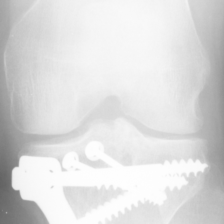

In [31]:

import os
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from IPython.display import display

model = densenet_radimagenet_ordinal
model.eval()

records = []
offset = 0

with torch.inference_mode():
    for images, labels in val_loader:
        logits = model(images.to(device)).float()

        targets = labels_to_ordinal(
            labels.to(device),
            num_classes=NUM_CLASSES
        )

        losses = F.binary_cross_entropy_with_logits(
            logits,
            targets,
            reduction="none"
        ).mean(dim=1).cpu().numpy()

        preds = ordinal_logits_to_class(
            logits
        ).cpu().numpy()

        logits_np = logits.cpu().numpy()

        for j in range(len(labels)):
            idx = offset + j
            path = val_dataset.samples[idx][0]

            records.append({
                "idx": idx,
                "path": path,
                "true": int(labels[j]),
                "pred": int(preds[j]),
                "loss": float(losses[j]),
                "logits": logits_np[j],
                "input_min": float(images[j].min()),
                "input_max": float(images[j].max()),
            })

        offset += len(labels)

records.sort(key=lambda x: x["loss"], reverse=True)

print("TOP 10 HIGHEST-LOSS IMAGES")

for r in records[:10]:
    print(
        f"idx={r['idx']} "
        f"true=KL{r['true']} "
        f"pred=KL{r['pred']} "
        f"loss={r['loss']:.4f}"
    )
    print("File:", os.path.basename(r["path"]))
    print("Logits:", np.round(r["logits"], 2))
    print(
        "Input range:",
        r["input_min"],
        r["input_max"]
    )
    print()

print("Images with loss > 2:",
      sum(r["loss"] > 2 for r in records))

print("Images with loss > 10:",
      sum(r["loss"] > 10 for r in records))

print("\nWORST IMAGE:")
worst = records[0]

print("Path:", worst["path"])
display(Image.open(worst["path"]))


In [32]:

import copy
import torch
import torch.nn as nn

# 1. Original pretrained backbone
fresh = create_densenet121_radimagenet_ordinal(
    rad_state, num_classes=NUM_CLASSES
).to(device).eval()

# 2. Fine-tuned model
trained = densenet_radimagenet_ordinal.eval()

# 3. Fine-tuned weights + original BN running statistics
bn_reset = copy.deepcopy(trained)
fresh_modules = dict(fresh.named_modules())

with torch.no_grad():
    for name, module in bn_reset.named_modules():
        if isinstance(module, nn.BatchNorm2d):
            original = fresh_modules[name]

            module.running_mean.copy_(
                original.running_mean
            )
            module.running_var.copy_(
                original.running_var
            )
            module.num_batches_tracked.copy_(
                original.num_batches_tracked
            )

bn_reset.eval()


def inspect_sample(model, idx):
    image, label = val_dataset[idx]
    x = image.unsqueeze(0).to(device)

    with torch.inference_mode():
        features = model.features(x)
        logits = model(x)

    return (
        float(features.abs().max()),
        float(logits.abs().max()),
        logits.cpu().numpy().round(2)
    )


for idx in [736, 737, 738]:
    print(f"\nIMAGE INDEX: {idx}")

    for name, model in [
        ("Fresh", fresh),
        ("Trained", trained),
        ("Trained + original BN", bn_reset)
    ]:
        feat_max, logit_max, logits = inspect_sample(
            model, idx
        )

        print(
            f"{name:24s} "
            f"Feature max={feat_max:.2f}, "
            f"Logit max={logit_max:.2f}"
        )
        print("  Logits:", logits)


Expected backbone tensors: 725
Loaded backbone tensors: 725
Missing backbone tensors: []
RadImageNet backbone loaded successfully!

IMAGE INDEX: 736
Fresh                    Feature max=0.38, Logit max=0.03
  Logits: [[-0.03 -0.01 -0.01 -0.03]]
Trained                  Feature max=0.30, Logit max=2.33
  Logits: [[ 0.9   0.06 -0.98 -2.33]]
Trained + original BN    Feature max=0.40, Logit max=2.45
  Logits: [[ 0.95  0.08 -1.03 -2.45]]

IMAGE INDEX: 737
Fresh                    Feature max=0.90, Logit max=0.03
  Logits: [[-0.02 -0.   -0.   -0.03]]
Trained                  Feature max=245228.28, Logit max=57779.75
  Logits: [[ 17704.07  -1192.76 -25057.47 -57779.76]]
Trained + original BN    Feature max=0.71, Logit max=3.02
  Logits: [[ 1.41  0.41 -0.99 -3.02]]

IMAGE INDEX: 738
Fresh                    Feature max=141.83, Logit max=0.31
  Logits: [[-0.31  0.16  0.25  0.09]]
Trained                  Feature max=0.48, Logit max=2.62
  Logits: [[ 0.97  0.04 -1.12 -2.62]]
Trained + original B

In [33]:

import copy
import numpy as np
import torch
from torch.utils.data import DataLoader
from torchvision import datasets
from torch.optim.swa_utils import update_bn

# Preserve original fine-tuned model
original_model = densenet_radimagenet_ordinal.eval()

# Separate copy for BN recalibration
calibrated_model = copy.deepcopy(original_model).to(device)

# Training images without random augmentations
calibration_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=val_test_transforms
)

calibration_loader = DataLoader(
    calibration_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

# Recalculate BatchNorm statistics.
# Does not modify learned parameters.
update_bn(
    calibration_loader,
    calibrated_model,
    device=device
)

calibrated_model.eval()

# Validation using existing notebook function
metrics, preds, labels = validate_ordinal(
    model=calibrated_model,
    loader=val_loader,
    criterion=criterion_ordinal_rad,
    device=device,
    num_classes=NUM_CLASSES
)

print("=== RECALIBRATED MODEL ===")
print(f"Validation loss: {metrics['loss']:.4f}")
print(f"Macro F1: {metrics['f1_macro']:.2f}%")
print(f"Balanced Accuracy: {metrics['balanced_accuracy']:.2f}%")
print(f"QWK: {metrics['qwk']:.4f}")

print("\nPredicted class distribution:")
print(np.bincount(preds, minlength=NUM_CLASSES))

print("\nProblematic images:")
for idx in [736, 737, 738]:
    image, label = val_dataset[idx]

    with torch.inference_mode():
        logits = calibrated_model(
            image.unsqueeze(0).to(device)
        )

    print(
        f"idx={idx}, true=KL{label}, "
        f"max_logit={logits.abs().max().item():.2f}, "
        f"logits={logits.cpu().numpy().round(2)}"
    )


=== RECALIBRATED MODEL ===
Validation loss: 78.0317
Macro F1: 11.01%
Balanced Accuracy: 21.14%
QWK: 0.1136

Predicted class distribution:
[  0 650 176   0   0]

Problematic images:
idx=736, true=KL3, max_logit=2.18, logits=[[ 0.79 -0.   -0.97 -2.18]]
idx=737, true=KL3, max_logit=2.19, logits=[[ 0.88  0.1  -0.9  -2.19]]
idx=738, true=KL3, max_logit=2.49, logits=[[ 0.86 -0.04 -1.14 -2.49]]


In [34]:

import numpy as np
import torch
import torch.nn.functional as F

def find_extreme_predictions(model, loader, dataset, top_k=10):
    model.eval()
    records = []
    offset = 0

    with torch.inference_mode():
        for images, labels in loader:
            logits = model(images.to(device)).float()
            targets = labels_to_ordinal(
                labels.to(device),
                num_classes=NUM_CLASSES
            )

            losses = F.binary_cross_entropy_with_logits(
                logits, targets, reduction="none"
            ).mean(dim=1)

            preds = ordinal_logits_to_class(logits)

            for j in range(len(labels)):
                records.append({
                    "idx": offset + j,
                    "true": int(labels[j]),
                    "pred": int(preds[j]),
                    "loss": float(losses[j]),
                    "max_logit": float(logits[j].abs().max()),
                    "logits": logits[j].cpu().tolist()
                })

            offset += len(labels)

    records.sort(key=lambda r: r["loss"], reverse=True)

    total_loss = sum(r["loss"] for r in records)

    print("TOP EXTREME SAMPLES")
    for r in records[:top_k]:
        filename = dataset.samples[r["idx"]][0].split("/")[-1]

        print(
            f"idx={r['idx']} | {filename} | "
            f"KL{r['true']} -> KL{r['pred']} | "
            f"loss={r['loss']:.2f} | "
            f"max_logit={r['max_logit']:.2f}"
        )

    print("\nSummary")
    print("Samples with loss > 10:",
          sum(r["loss"] > 10 for r in records))
    print("Samples with |logit| > 100:",
          sum(r["max_logit"] > 100 for r in records))
    print("Largest sample loss share:",
          round(100 * records[0]["loss"] / total_loss, 2),
          "%")

    return records


print("=== ORIGINAL MODEL ===")
original_records = find_extreme_predictions(
    densenet_radimagenet_ordinal,
    val_loader,
    val_dataset
)

print("\n=== CALIBRATED MODEL ===")
calibrated_records = find_extreme_predictions(
    calibrated_model,
    val_loader,
    val_dataset
)


=== ORIGINAL MODEL ===
TOP EXTREME SAMPLES
idx=737 | 9375300L.png | KL3 -> KL1 | loss=6562.56 | max_logit=57779.80
idx=824 | 9971710L.png | KL4 -> KL1 | loss=1.31 | max_logit=2.69
idx=821 | 9824005L.png | KL4 -> KL1 | loss=1.30 | max_logit=2.65
idx=799 | 9070207R.png | KL4 -> KL1 | loss=1.29 | max_logit=2.61
idx=806 | 9267719R.png | KL4 -> KL2 | loss=1.29 | max_logit=2.64
idx=816 | 9645612L.png | KL4 -> KL1 | loss=1.29 | max_logit=2.57
idx=818 | 9757953L.png | KL4 -> KL1 | loss=1.28 | max_logit=2.55
idx=808 | 9387265L.png | KL4 -> KL2 | loss=1.25 | max_logit=2.65
idx=802 | 9127180L.png | KL4 -> KL2 | loss=1.25 | max_logit=2.54
idx=815 | 9637958R.png | KL4 -> KL2 | loss=1.24 | max_logit=2.52

Summary
Samples with loss > 10: 1
Samples with |logit| > 100: 1
Largest sample loss share: 94.15 %

=== CALIBRATED MODEL ===
TOP EXTREME SAMPLES
idx=263 | 9784291L.png | KL0 -> KL2 | loss=54627.11 | max_logit=436685.97
idx=139 | 9399129L.png | KL0 -> KL2 | loss=8963.18 | max_logit=79794.64
idx=17 |

In [35]:

import torch

STAGES = [
    "features.conv0",
    "features.norm0",
    "features.pool0",
    "features.denseblock1",
    "features.transition1",
    "features.denseblock2",
    "features.transition2",
    "features.denseblock3",
    "features.transition3",
    "features.denseblock4",
    "features.norm5",
]

def inspect_activations(model, image_idx):
    model.eval()
    activations = {}
    hooks = []

    modules = dict(model.named_modules())

    for name in STAGES:
        def make_hook(stage_name):
            def hook(module, inputs, output):
                activations[stage_name] = (
                    output.detach().float().abs().max().item()
                )
            return hook

        hooks.append(
            modules[name].register_forward_hook(
                make_hook(name)
            )
        )

    try:
        image, label = val_dataset[image_idx]
        image = image.unsqueeze(0).to(device)

        with torch.inference_mode():
            logits = model(image)

        print(f"\nImage {image_idx} | True KL{label}")
        print("-" * 45)

        first_extreme = None

        for name, value in activations.items():
            print(f"{name:27s} {value:12.3f}")

            if value > 100 and first_extreme is None:
                first_extreme = name

        print("\nFirst stage with activation > 100:",
              first_extreme)

        print("Logits:", logits.cpu().numpy().round(2))

    finally:
        for hook in hooks:
            hook.remove()


print("=== ORIGINAL: PROBLEMATIC KL3 ===")
inspect_activations(
    densenet_radimagenet_ordinal, 737
)

print("\n=== CALIBRATED: PROBLEMATIC KL0 ===")
inspect_activations(
    calibrated_model, 263
)

print("\n=== ORIGINAL: SAME KL0 ===")
inspect_activations(
    densenet_radimagenet_ordinal, 263
)


=== ORIGINAL: PROBLEMATIC KL3 ===

Image 737 | True KL3
---------------------------------------------
features.conv0                   148.673
features.norm0                    11.910
features.pool0                    11.910
features.denseblock1             405.860
features.transition1              72.468
features.denseblock2             458.435
features.transition2             117.088
features.denseblock3           49005.410
features.transition3         9741911.000
features.denseblock4        17330764.000
features.norm5                245228.281

First stage with activation > 100: features.conv0
Logits: [[ 17704.07  -1192.76 -25057.47 -57779.76]]

=== CALIBRATED: PROBLEMATIC KL0 ===

Image 263 | True KL0
---------------------------------------------
features.conv0                   103.724
features.norm0                    13.789
features.pool0                    13.789
features.denseblock1             766.481
features.transition1              93.845
features.denseblock2             4

In [36]:
"""Two-stage DenseNet121 + RadImageNet + ordinal BCE experiment.

Designed to run INSIDE the existing knee osteoarthritis notebook, after defining
train_loader, val_loader, val_dataset, BATCH_SIZE, NUM_CLASSES and device.

This is an experimental BN-control strategy, not a guaranteed improvement.
It uses the original training split, 0.5 ordinal thresholds, and validation
Macro F1 for selection. No test data are used for training or tuning.
"""

from __future__ import annotations

from collections import OrderedDict
from pathlib import Path
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchvision import models
from torch.utils.data import SequentialSampler
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, cohen_kappa_score,
    confusion_matrix,
)
from huggingface_hub import hf_hub_download
import wandb

RUN_NAME_V2 = "densenet121_radimagenet_ordinal_v2_two_stage"
SEED_V2 = 4747
HEAD_EPOCHS = 4
FINETUNE_EPOCHS = 8       # Diagnostic run; extend only after inspecting results
BACKBONE_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-4
GRAD_CLIP_NORM = 1.0
WARNING_LOGIT = 100.0
ABORT_LOGIT = 1000.0
EARLY_STOP_PATIENCE = 4
MIN_DELTA_F1 = 0.1         # percentage points

FROZEN_EARLY_NAMES = (
    "norm0", "denseblock1", "transition1", "denseblock2", "transition2"
)
LATE_TRAINABLE_NAMES = (
    "denseblock3", "transition3", "denseblock4", "norm5"
)


def set_seed_v2(seed=SEED_V2):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def download_rad_densenet_weights():
    path = hf_hub_download(
        repo_id="Lab-Rasool/RadImageNet", filename="DenseNet121.pt"
    )
    state = torch.load(path, map_location="cpu", weights_only=True)
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    if isinstance(state, dict) and "model_state_dict" in state:
        state = state["model_state_dict"]
    if not isinstance(state, (dict, OrderedDict)):
        raise TypeError(f"Unexpected checkpoint type: {type(state)}")
    return state


def build_rad_densenet121_ordinal_v2(rad_state, num_classes=5):
    model = models.densenet121(weights=None)
    expected = model.state_dict()
    mapped = {}

    for old_key, tensor in rad_state.items():
        # Verified key format: backbone.0.conv0.weight -> features.conv0.weight
        if not old_key.startswith("backbone.0."):
            continue
        key = "features." + old_key[len("backbone.0."):]
        if key not in expected:
            raise RuntimeError(f"Unrecognized backbone weight: {old_key} -> {key}")
        if expected[key].shape != tensor.shape:
            raise RuntimeError(f"Shape mismatch at {key}: {expected[key].shape} vs {tensor.shape}")
        mapped[key] = tensor

    mandatory_keys = [
        k for k in expected if k.startswith("features.")
        and not k.endswith("num_batches_tracked")
    ]
    missing_backbone = sorted(set(mandatory_keys) - set(mapped))
    if missing_backbone:
        raise RuntimeError(f"Missing RadImageNet backbone weights: {missing_backbone[:20]}")

    result = model.load_state_dict(mapped, strict=False)
    unexpected = result.unexpected_keys
    missing_other = [
        k for k in result.missing_keys
        if not k.startswith("classifier.") and not k.endswith("num_batches_tracked")
    ]
    if unexpected or missing_other:
        raise RuntimeError(f"Load failed: unexpected={unexpected}, missing={missing_other}")

    print(f"RadImageNet backbone: expected {sum(k.startswith('features.') for k in expected)} tensors, loaded {len(mapped)}; missing required = 0")
    in_features = model.classifier.in_features
    model.classifier = nn.Sequential(
        nn.Dropout(0.5), nn.Linear(in_features, 512), nn.ReLU(),
        nn.Dropout(0.3), nn.Linear(512, num_classes - 1)
    )
    return model


def set_stage_trainable(model, stage):
    for param in model.parameters():
        param.requires_grad_(False)

    for param in model.classifier.parameters():
        param.requires_grad_(True)

    if stage == "finetune":
        for name in LATE_TRAINABLE_NAMES:
            for param in getattr(model.features, name).parameters():
                param.requires_grad_(True)
    elif stage != "head":
        raise ValueError(f"Unknown stage: {stage}")


def set_stage_mode_each_epoch(model, stage):
    # train() ALWAYS resets every BN; this must be reapplied every epoch.
    model.train()
    if stage == "head":
        # All pretrained BN statistics are frozen; head keeps Dropout active.
        model.features.eval()
    elif stage == "finetune":
        # Freeze early BN stats; late BN stats can adapt on train only.
        for name in FROZEN_EARLY_NAMES:
            getattr(model.features, name).eval()
    else:
        raise ValueError(stage)


def make_optimizer_v2(model, stage):
    groups = []
    if stage == "finetune":
        backbone = []
        for name in LATE_TRAINABLE_NAMES:
            backbone.extend(getattr(model.features, name).parameters())
        groups.append({"params": backbone, "lr": BACKBONE_LR})
    groups.append({"params": list(model.classifier.parameters()), "lr": HEAD_LR})
    opt = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

    trainable_ids = {id(p) for p in model.parameters() if p.requires_grad}
    optimizer_ids = {id(p) for g in opt.param_groups for p in g["params"]}
    if trainable_ids != optimizer_ids:
        raise RuntimeError("Optimizer does not match the model's trainable parameters!")
    return opt


def get_ordinal_targets(labels, num_classes=5):
    thresholds = torch.arange(num_classes - 1, device=labels.device)
    return (labels[:, None] > thresholds[None, :]).float()


def predict_ordinal(logits):
    return (torch.sigmoid(logits) > 0.5).sum(dim=1)


def train_one_epoch_v2(model, loader, optimizer, device, stage, num_classes=5):
    set_stage_mode_each_epoch(model, stage)
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    max_grad_norm = 0.0

    for batch_idx, (images, labels) in enumerate(loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        targets = get_ordinal_targets(labels, num_classes)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = F.binary_cross_entropy_with_logits(logits, targets)

        if not torch.isfinite(logits).all() or not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite train logits/loss in {stage}, batch {batch_idx}")

        loss.backward()
        grad_norm = nn.utils.clip_grad_norm_(
            [p for p in model.parameters() if p.requires_grad],
            max_norm=GRAD_CLIP_NORM, error_if_nonfinite=True
        )
        max_grad_norm = max(max_grad_norm, float(grad_norm))
        optimizer.step()

        bs = labels.size(0)
        total_samples += bs
        total_loss += float(loss) * bs
        total_correct += int((predict_ordinal(logits) == labels).sum())

    return {
        "loss": total_loss / total_samples,
        "accuracy": 100.0 * total_correct / total_samples,
        "max_grad_norm_before_clipping": max_grad_norm,
    }


@torch.no_grad()
def validate_v2(model, loader, device, num_classes=5):
    model.eval()
    all_preds, all_labels = [], []
    batch_losses, all_abs_logits = [], []
    all_sample_losses = []
    max_logit = 0.0
    nonfinite_count = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images).float()
        targets = get_ordinal_targets(labels, num_classes)
        if not torch.isfinite(logits).all():
            nonfinite_count += int((~torch.isfinite(logits)).any(dim=1).sum())
            raise FloatingPointError("Non-finite validation logits")

        per_sample_loss = F.binary_cross_entropy_with_logits(
            logits, targets, reduction="none"
        ).mean(dim=1)
        preds = predict_ordinal(logits)
        all_preds.extend(preds.cpu().numpy().tolist())
        all_labels.extend(labels.cpu().numpy().tolist())
        all_sample_losses.extend(per_sample_loss.cpu().numpy().tolist())
        all_abs_logits.extend(logits.abs().amax(dim=1).cpu().numpy().tolist())

    preds = np.asarray(all_preds, dtype=int)
    labels = np.asarray(all_labels, dtype=int)
    losses = np.asarray(all_sample_losses, dtype=float)
    abs_logits = np.asarray(all_abs_logits, dtype=float)
    worst_idx = int(np.argmax(losses))
    hist = np.bincount(preds, minlength=num_classes)
    metric = {
        "loss": float(np.mean(losses)),
        "accuracy": 100.0 * accuracy_score(labels, preds),
        "balanced_accuracy": 100.0 * balanced_accuracy_score(labels, preds),
        "f1_macro": 100.0 * f1_score(labels, preds, labels=list(range(num_classes)), average="macro", zero_division=0),
        "qwk": float(cohen_kappa_score(labels, preds, weights="quadratic")),
        "mae": float(np.mean(np.abs(preds - labels))),
        "max_abs_logit": float(np.max(abs_logits)),
        "num_abs_logit_gt_100": int(np.sum(abs_logits > WARNING_LOGIT)),
        "num_loss_gt_10": int(np.sum(losses > 10.0)),
        "max_single_image_loss": float(np.max(losses)),
        "worst_idx": worst_idx,
        "worst_true": int(labels[worst_idx]),
        "worst_pred": int(preds[worst_idx]),
        "worst_loss_share_percent": float(100.0 * losses[worst_idx] / max(losses.sum(), 1e-12)),
        "predicted_class_counts": hist.tolist(),
        "preds": preds,
        "labels": labels,
    }
    return metric


def best_checkpoint_v2(model, stage, epoch, val_metrics, path, config):
    torch.save({
        "model_state_dict": model.state_dict(),
        "stage": stage,
        "epoch": epoch,
        "val_f1_macro": val_metrics["f1_macro"],
        "val_qwk": val_metrics["qwk"],
        "val_max_abs_logit": val_metrics["max_abs_logit"],
        "seed": SEED_V2,
        "config": config,
    }, str(path))


def restore_model_v2(model, path, device):
    checkpoint = torch.load(str(path), map_location=device, weights_only=True)
    model.load_state_dict(checkpoint["model_state_dict"])
    return checkpoint


def fit_stage_v2(model, stage, loader, val_loader, device, epochs, run,
                 checkpoint_path, config, global_step_start=0):
    set_stage_trainable(model, stage)
    optimizer = make_optimizer_v2(model, stage)
    scheduler = None if stage == "head" else ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )

    best_f1 = -1.0
    best_epoch = None
    not_improved = 0
    unstable = False

    for epoch in range(1, epochs + 1):
        train_stats = train_one_epoch_v2(
            model, loader, optimizer, device, stage, num_classes=config["num_classes"]
        )
        val = validate_v2(model, val_loader, device, num_classes=config["num_classes"])
        if scheduler is not None and val["max_abs_logit"] <= WARNING_LOGIT:
            scheduler.step(val["loss"])

        global_epoch = global_step_start + epoch
        log_data = {
            "global_epoch": global_epoch, "stage": stage,
            "train/loss": train_stats["loss"],
            "train/accuracy": train_stats["accuracy"],
            "train/max_grad_norm": train_stats["max_grad_norm_before_clipping"],
            "val/loss": val["loss"],
            "val/accuracy": val["accuracy"],
            "val/f1_macro": val["f1_macro"],
            "val/balanced_accuracy": val["balanced_accuracy"],
            "val/qwk": val["qwk"],
            "val/mae": val["mae"],
            "val/max_abs_logit": val["max_abs_logit"],
            "val/num_abs_logit_gt_100": val["num_abs_logit_gt_100"],
            "val/max_single_image_loss": val["max_single_image_loss"],
            "val/worst_loss_share_percent": val["worst_loss_share_percent"],
            "val/predicted_classes": len(set(val["preds"].tolist())),
        }
        for i, group in enumerate(optimizer.param_groups):
            log_data[f"lr/group_{i}"] = group["lr"]
        for c, count in enumerate(val["predicted_class_counts"]):
            log_data[f"val/pred_count_KL{c}"] = count
        run.log(log_data)

        print(
            f"[{stage}] {epoch}/{epochs} "
            f"train_loss={train_stats['loss']:.4f} "
            f"val_loss={val['loss']:.4f} "
            f"F1={val['f1_macro']:.2f}% "
            f"BalAcc={val['balanced_accuracy']:.2f}% "
            f"QWK={val['qwk']:.4f} "
            f"max|logit|={val['max_abs_logit']:.1f} "
            f"pred_counts={val['predicted_class_counts']}"
        )

        if val["max_abs_logit"] > WARNING_LOGIT:
            print(f"  WARNING: extreme logit(s). Worst val index={val['worst_idx']}, "
                  f"loss={val['max_single_image_loss']:.1f}. Not checkpointing this epoch.")
            if val["max_abs_logit"] > ABORT_LOGIT:
                print("  ABORT: explosive logits. Stop before another epoch.")
                unstable = True
                break
            not_improved += 1
            continue

        # Save only numerically stable checkpoints with max |logit| <= 100.
        # This conservative threshold is a diagnostic policy, not a universal ML rule.
        if val["f1_macro"] > best_f1 + (MIN_DELTA_F1 if best_epoch is not None else 0):
            best_f1 = val["f1_macro"]
            best_epoch = epoch
            not_improved = 0
            best_checkpoint_v2(model, stage, epoch, val, checkpoint_path, config)
            print(f"  saved best {stage} checkpoint (F1={best_f1:.2f}%)")
        else:
            not_improved += 1

        if stage == "finetune" and not_improved >= EARLY_STOP_PATIENCE:
            print(f"  Early stopping after {EARLY_STOP_PATIENCE} epochs without improvement.")
            break

    if best_epoch is None:
        return {"status": "unstable" if unstable else "no_checkpoint", "best_epoch": None}
    restore_model_v2(model, checkpoint_path, device)
    return {
        "status": "aborted_instability" if unstable else "ok",
        "best_epoch": best_epoch,
        "best_f1": best_f1,
        "checkpoint_path": str(checkpoint_path),
    }


def run_radimagenet_v2(train_loader, val_loader, val_dataset, device, batch_size=32,
                       num_classes=5, output_dir=None):
    set_seed_v2()
    if not isinstance(val_loader.sampler, SequentialSampler):
        raise ValueError("val_loader must use shuffle=False for diagnostics")
    if list(train_loader.dataset.classes) != list(val_loader.dataset.classes):
        raise ValueError("train and validation class order must match")

    output_dir = Path(output_dir or ("/kaggle/working" if Path("/kaggle/working").exists() else "."))
    output_dir.mkdir(parents=True, exist_ok=True)
    head_ckpt = output_dir / f"{RUN_NAME_V2}_head_best.pth"
    finetune_ckpt = output_dir / f"{RUN_NAME_V2}_finetune_best.pth"

    raw_state = download_rad_densenet_weights()
    model = build_rad_densenet121_ordinal_v2(raw_state, num_classes).to(device)
    config = {
        "architecture": "densenet121",
        "pretraining_source": "radimagenet",
        "run_name": RUN_NAME_V2,
        "num_classes": num_classes,
        "img_size": 224,
        "batch_size": batch_size,
        "seed": SEED_V2,
        "loss": "ordinal_bce",
        "threshold": 0.5,
        "sampler": "sqrt_weighted_random_sampler_existing_train_loader",
        "stage1": "classifier_only_features_eval",
        "stage2": "block3_4_finetune_early_bn_eval_late_bn_train",
        "stage1_epochs": HEAD_EPOCHS,
        "stage2_epochs": FINETUNE_EPOCHS,
        "lr_stage1_head": HEAD_LR,
        "lr_stage2_backbone": BACKBONE_LR,
        "lr_stage2_head": HEAD_LR,
        "weight_decay": WEIGHT_DECAY,
        "grad_clip_norm": GRAD_CLIP_NORM,
        "abort_abs_logit": ABORT_LOGIT,
        "checkpoint_metric": "validation_macro_f1",
    }

    run = wandb.init(
        project="knee-xai", name=RUN_NAME_V2, config=config,
        tags=["densenet121", "radimagenet", "ordinal", "two-stage", "bn-controlled", "diagnostic-v2"]
    )
    try:
        head_info = fit_stage_v2(
            model, "head", train_loader, val_loader, device, HEAD_EPOCHS,
            run, head_ckpt, config, global_step_start=0
        )
        if head_info["status"] != "ok":
            print("Stage 1 was unstable. Do not start fine-tuning.")
            run.summary["status"] = "failed_stage1"
            return model, {"head": head_info, "finetune": None}

        # fit_stage_v2 restores best head-only checkpoint by design.
        finetune_info = fit_stage_v2(
            model, "finetune", train_loader, val_loader, device,
            FINETUNE_EPOCHS, run, finetune_ckpt, config,
            global_step_start=HEAD_EPOCHS
        )

        # Compare stages on validation and retain the better checkpoint.
        candidates = [("head", head_ckpt)]
        if finetune_info["status"] == "ok":
            candidates.append(("finetune", finetune_ckpt))

        scores = {}
        for label, path in candidates:
            restore_model_v2(model, path, device)
            scores[label] = validate_v2(model, val_loader, device, num_classes)
            print(f"Final {label}: F1={scores[label]['f1_macro']:.2f}%, "
                  f"max|logit|={scores[label]['max_abs_logit']:.1f}")

        selected_stage, selected_path = max(
            candidates, key=lambda pair: scores[pair[0]]["f1_macro"]
        )
        restore_model_v2(model, selected_path, device)
        model.eval()
        selected_metrics = scores[selected_stage]
        run.summary["selected_stage"] = selected_stage
        run.summary["best_val_f1_macro"] = selected_metrics["f1_macro"]
        run.summary["best_val_qwk"] = selected_metrics["qwk"]
        run.summary["best_val_max_abs_logit"] = selected_metrics["max_abs_logit"]
        run.summary["selected_checkpoint"] = str(selected_path)
        run.summary["status"] = "completed" if finetune_info["status"] == "ok" else "unstable_finetune"

        artifact = wandb.Artifact(
            name=RUN_NAME_V2, type="model",
            metadata={"selected_stage": selected_stage, "selection_metric": "val_macro_f1"}
        )
        artifact.add_file(str(selected_path))
        run.log_artifact(artifact, aliases=["best"])
        print(f"SELECTED {selected_stage}: {selected_path}")
        return model, {
            "head": head_info, "finetune": finetune_info,
            "selected_stage": selected_stage,
            "selected_metrics": selected_metrics,
            "selected_checkpoint": str(selected_path),
        }
    finally:
        run.finish()

In [37]:
model_v2, results_v2 = run_radimagenet_v2(
    train_loader=train_loader,
    val_loader=val_loader,
    val_dataset=val_dataset,
    device=device,
    batch_size=BATCH_SIZE,
    num_classes=NUM_CLASSES,
)

print("\n=== V2 EXPERIMENT SUMMARY ===")
print("Head:", results_v2.get("head"))
print("Fine-tuning:", results_v2.get("finetune"))
if "selected_metrics" in results_v2:
    m = results_v2["selected_metrics"]
    print("Selected stage:", results_v2["selected_stage"])
    print("Selected checkpoint:", results_v2["selected_checkpoint"])
    print(f"Validation Macro F1: {m['f1_macro']:.2f}%")
    print(f"Validation Balanced Accuracy: {m['balanced_accuracy']:.2f}%")
    print(f"Validation QWK: {m['qwk']:.4f}")
    print(f"Maximum |logit|: {m['max_abs_logit']:.2f}")
    print("Predicted KL class counts:", m['predicted_class_counts'])


RadImageNet backbone: expected 725 tensors, loaded 725; missing required = 0


[head] 1/4 train_loss=0.6558 val_loss=0.6579 F1=10.36% BalAcc=19.82% QWK=-0.0038 max|logit|=18.1 pred_counts=[0, 665, 161, 0, 0]
  saved best head checkpoint (F1=10.36%)
[head] 2/4 train_loss=0.6227 val_loss=0.6307 F1=6.25% BalAcc=20.00% QWK=0.0000 max|logit|=12.4 pred_counts=[0, 826, 0, 0, 0]
[head] 3/4 train_loss=0.6068 val_loss=0.6135 F1=7.97% BalAcc=19.10% QWK=-0.0122 max|logit|=8.1 pred_counts=[0, 753, 73, 0, 0]
[head] 4/4 train_loss=0.5982 val_loss=0.5921 F1=10.03% BalAcc=18.55% QWK=-0.0015 max|logit|=11.3 pred_counts=[0, 602, 224, 0, 0]
[finetune] 1/8 train_loss=0.6159 val_loss=0.5369 F1=8.17% BalAcc=20.00% QWK=0.0000 max|logit|=1.5 pred_counts=[0, 0, 826, 0, 0]
  saved best finetune checkpoint (F1=8.17%)
[finetune] 2/8 train_loss=0.5530 val_loss=0.5114 F1=8.17% BalAcc=20.00% QWK=0.0000 max|logit|=2.3 pred_counts=[0, 0, 826, 0, 0]
[finetune] 3/8 train_loss=0.5448 val_loss=7.6740 F1=8.17% BalAcc=20.00% QWK=0.0000 max|logit|=93663.0 pred_counts=[0, 0, 826, 0, 0]
  ABORT: explosive

global_epoch,▁▂▃▅▆▇█
lr/group_0,████▁▁▁
lr/group_1,▁▁▁
train/accuracy,█▁▁▄▁▅▂
train/loss,█▆▅▄▅▂▁
train/max_grad_norm,█▅▃▃▇▁▁
val/accuracy,▂▁▁▂███
val/balanced_accuracy,▇█▄▁███
val/f1_macro,█▁▄▇▄▄▄
val/loss,▁▁▁▁▁▁█
+12,...



=== V2 EXPERIMENT SUMMARY ===
Head: {'status': 'ok', 'best_epoch': 1, 'best_f1': 10.362553012972201, 'checkpoint_path': '/kaggle/working/densenet121_radimagenet_ordinal_v2_two_stage_head_best.pth'}
Fine-tuning: {'status': 'aborted_instability', 'best_epoch': 1, 'best_f1': 8.169556840077071, 'checkpoint_path': '/kaggle/working/densenet121_radimagenet_ordinal_v2_two_stage_finetune_best.pth'}
Selected stage: head
Selected checkpoint: /kaggle/working/densenet121_radimagenet_ordinal_v2_two_stage_head_best.pth
Validation Macro F1: 10.36%
Validation Balanced Accuracy: 19.82%
Validation QWK: -0.0038
Maximum |logit|: 18.09
Predicted KL class counts: [0, 665, 161, 0, 0]


## DenseNet + ordinall loss + class aware

In [23]:

import torch
import numpy as np
import wandb
import inspect

from torch import nn
from torch.optim.lr_scheduler import ReduceLROnPlateau

SEED = 4747
RUN_NAME = "densenet121_imagenet_classaware_ordinal_v1"

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Ensure the training function supports a separate
# validation criterion, as in the ResNet50 experiment.
assert "val_criterion" in inspect.signature(
    train_model_ordinal
).parameters, (
    "train_model_ordinal must accept val_criterion. "
    "Run the updated function definition first."
)

# 1. Fresh ImageNet-pretrained DenseNet121
dense_ca_model = create_densenet121_ordinal_model(
    num_classes=NUM_CLASSES
).to(device)

# 2. Class-aware loss for training
dense_ca_train_criterion = ClassAwareOrdinalBCELoss(
    focus_class=1,
    class_multiplier=1.5
)

# Standard BCE for validation
dense_ca_val_criterion = nn.BCEWithLogitsLoss()

# 3. Optimizer: same parameters as DenseNet121 v3
dense_ca_backbone_params = (
    list(dense_ca_model.features.denseblock3.parameters())
    + list(dense_ca_model.features.transition3.parameters())
    + list(dense_ca_model.features.denseblock4.parameters())
    + list(dense_ca_model.features.norm5.parameters())
)

dense_ca_optimizer = torch.optim.AdamW(
    [
        {
            "params": dense_ca_backbone_params,
            "lr": 1e-5
        },
        {
            "params": dense_ca_model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

# Verify that the optimizer covers all trainable params
trainable_ids = {
    id(p)
    for p in dense_ca_model.parameters()
    if p.requires_grad
}

optimizer_ids = {
    id(p)
    for group in dense_ca_optimizer.param_groups
    for p in group["params"]
}

assert trainable_ids == optimizer_ids, (
    "Optimizer parameters do not match trainable parameters!"
)

# 4. Scheduler
dense_ca_scheduler = ReduceLROnPlateau(
    dense_ca_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

# 5. Experiment configuration
dense_ca_config = {
    "model_name": RUN_NAME,
    "architecture": "densenet121",
    "training_stage": "ordinal_finetune_block3_4",

    "pretraining_source": "imagenet",
    "parent_model": None,

    "unfrozen_layers": [
        "denseblock3",
        "transition3",
        "denseblock4",
        "norm5",
        "classifier"
    ],

    "num_classes": NUM_CLASSES,
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": 35,

    "optimizer": "adamw",
    "learning_rate": {
        "backbone": 1e-5,
        "head": 1e-4
    },
    "weight_decay": 1e-4,

    "scheduler": "reduce_lr_on_plateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,

    "early_stopping_patience": 6,
    "early_stopping_min_delta": 0.1,

    "loss": "class_aware_ordinal_bce",
    "validation_loss": "ordinal_bce",

    "focus_class": 1,
    "class_multiplier": 1.5,

    "sampler": "sqrt_weighted_random_sampler",
    "selection_metric": "val_macro_f1",
    "ordinal_threshold": 0.5,
    "seed": SEED
}

print("DenseNet121 Class-aware configured.")
print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in dense_ca_model.parameters()
        if p.requires_grad
    )
)


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 229MB/s]


DenseNet121 Class-aware configured.
Trainable parameters: 6051076


In [26]:

dense_ca_run = wandb.init(
    project="knee-xai",
    name=RUN_NAME,
    config=dense_ca_config,
    tags=[
        "densenet121",
        "imagenet",
        "ordinal",
        "class-aware-loss",
        "KL1",
        "fine-tuning",
        "sqrt-weighted-sampler"
    ]
)

dense_ca_run.define_metric("epoch")
dense_ca_run.define_metric("train/*", step_metric="epoch")
dense_ca_run.define_metric("val/*", step_metric="epoch")
dense_ca_run.define_metric("lr/*", step_metric="epoch")

dense_ca_checkpoint_path = f"{RUN_NAME}_best.pth"

# Train with class-aware BCE
(
    dense_ca_model,
    dense_ca_best_f1,
    dense_ca_best_epoch,
    dense_ca_checkpoint_path
) = train_model_ordinal(
    model=dense_ca_model,
    train_loader=train_loader,
    val_loader=val_loader,

    criterion=dense_ca_train_criterion,
    val_criterion=dense_ca_val_criterion,

    optimizer=dense_ca_optimizer,
    scheduler=dense_ca_scheduler,
    device=device,

    config=dense_ca_config,
    run=dense_ca_run,

    best_model_path=dense_ca_checkpoint_path,

    early_stopping=EarlyStopping(
        patience=6,
        min_delta=0.1
    ),

    num_classes=NUM_CLASSES
)

# Reload best checkpoint, evaluate and upload artifact
dense_ca_model, dense_ca_best_metrics = finalize_run_ordinal(
    model=dense_ca_model,
    val_loader=val_loader,

    criterion=dense_ca_val_criterion,

    device=device,
    config=dense_ca_config,
    run=dense_ca_run,

    best_epoch=dense_ca_best_epoch,
    best_val_f1=dense_ca_best_f1,

    best_model_path=dense_ca_checkpoint_path,
    artifact_name=RUN_NAME,

    num_classes=NUM_CLASSES
)

print("\n=== DENSENET121 CLASS-AWARE RESULTS ===")

print("Best epoch:", dense_ca_best_epoch)

print(
    f"Macro F1: "
    f"{dense_ca_best_metrics['f1_macro']:.2f}%"
)

print(
    f"Balanced Accuracy: "
    f"{dense_ca_best_metrics['balanced_accuracy']:.2f}%"
)

print(
    f"QWK: "
    f"{dense_ca_best_metrics['qwk']:.4f}"
)

for kl in range(NUM_CLASSES):
    print(
        f"KL{kl}: "
        f"F1={dense_ca_best_metrics[f'f1_KL{kl}']:.2f}% | "
        f"Precision={dense_ca_best_metrics[f'precision_KL{kl}']:.2f}% | "
        f"Recall={dense_ca_best_metrics[f'recall_KL{kl}']:.2f}%"
    )

print("\nCheckpoint:", dense_ca_checkpoint_path)


✓ Best model saved (Epoch 1) | Macro F1: 35.99%

Epoch 1/35
Train Loss: 0.4059 | Acc: 32.74%
Val Loss: 0.3705 | Acc: 35.47% | Balanced Acc: 37.34%
Macro F1: 35.99% | QWK: 0.5738
------------------------------------------------------------
✓ Best model saved (Epoch 2) | Macro F1: 47.77%

Epoch 2/35
Train Loss: 0.3633 | Acc: 40.00%
Val Loss: 0.3478 | Acc: 42.01% | Balanced Acc: 50.44%
Macro F1: 47.77% | QWK: 0.6371
------------------------------------------------------------
✓ Best model saved (Epoch 3) | Macro F1: 50.78%

Epoch 3/35
Train Loss: 0.3421 | Acc: 41.64%
Val Loss: 0.3210 | Acc: 45.28% | Balanced Acc: 52.83%
Macro F1: 50.78% | QWK: 0.6942
------------------------------------------------------------
✓ Best model saved (Epoch 4) | Macro F1: 52.64%

Epoch 4/35
Train Loss: 0.3208 | Acc: 45.31%
Val Loss: 0.3108 | Acc: 45.52% | Balanced Acc: 54.87%
Macro F1: 52.64% | QWK: 0.7001
------------------------------------------------------------
✓ Best model saved (Epoch 5) | Macro F1: 54.

epoch,▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
lr/group_0,████████████████████████▃▃▃▁
lr/group_1,████████████████████████▃▃▃▁
train/accuracy,▁▃▃▄▄▅▅▅▆▆▆▆▆▇▆▆▇▇▇▇▇█▇█████
train/loss,█▆▆▅▄▄▄▄▃▃▃▃▃▂▂▂▂▂▂▂▂▁▂▁▁▁▁▁
val/accuracy,▁▃▄▄▆▄▅▆▆▅▇▆▇█▇▆█▇▇▇▇██▇█▇▇▇
val/balanced_accuracy,▁▄▅▆▆▆▆▇▇▇█▇▇▇█▇███▇▇██▇████
val/f1_KL0,▁▃▅▄▆▃▄▇▆▄▆▆▇█▆▅▇▆▆▇▇▇▇▇▇▇▆▆
val/f1_KL1,▅▆▄▆▄▆▆▅▆▇▇▆▇▁▇█▆▆▆▅▃▆▅▃▅▆▆▆
val/f1_KL2,▁▄▄▄▆▃▅▃▄▅▇▂▄▄▆▄▆█▇▄▄█▇▅▇▆▇▇
+17,...



=== DENSENET121 CLASS-AWARE RESULTS ===
Best epoch: 22
Macro F1: 62.93%
Balanced Accuracy: 64.03%
QWK: 0.7730
KL0: F1=65.42% | Precision=74.13% | Recall=58.54%
KL1: F1=35.27% | Precision=26.78% | Recall=51.63%
KL2: F1=50.84% | Precision=62.33% | Recall=42.92%
KL3: F1=75.00% | Precision=79.79% | Recall=70.75%
KL4: F1=88.14% | Precision=81.25% | Recall=96.30%

Checkpoint: densenet121_imagenet_classaware_ordinal_v1_best.pth


# Expirement

In [40]:

import wandb
import torch
import torch.nn as nn
from pathlib import Path
from torchvision import models

# 1. Download checkpoint from Weights & Biases
api = wandb.Api()

artifact = api.artifact(
    "kkaterynabilyk-lviv-polytechnic-national-university/"
    "knee-xai/resnet50_ordinal_finetune_layer3_4_v4:v0",
    type="model"
)

artifact_dir = Path(
    artifact.download(
        root="/kaggle/working/resnet50_ordinal_v4"
    )
)

checkpoint_files = list(artifact_dir.rglob("*.pth"))

if len(checkpoint_files) != 1:
    raise RuntimeError(
        f"Expected one checkpoint, found: {checkpoint_files}"
    )

checkpoint_path = checkpoint_files[0]
print("Checkpoint:", checkpoint_path)

# 2. Load checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Best epoch:", checkpoint.get("epoch"))
print("Validation Macro F1:", checkpoint.get("val_macro_f1"))

# 3. Recreate exact ordinal architecture
model = models.resnet50(weights=None)

num_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(num_features, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, NUM_CLASSES - 1)
)

# 4. Load trained weights
model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(device)
model.eval()

print("ResNet50 ordinal loaded successfully!")


# Collect validation predictions
logits, labels = collect_ordinal_outputs(
    model, val_loader, device
)

probs = torch.sigmoid(logits).numpy()
y_true = labels.numpy()

def evaluate_thresholds(thresholds):
    preds = (
        probs > np.asarray(thresholds)
    ).sum(axis=1)

    f1 = f1_score(
        y_true, preds,
        labels=list(range(5)),
        average=None,
        zero_division=0
    )

    return {
        "t0": thresholds[0],
        "t1": thresholds[1],
        "macro_f1": f1.mean() * 100,
        "f1_kl1": f1[1] * 100,
        "f1_kl2": f1[2] * 100,
        "qwk": cohen_kappa_score(
            y_true, preds, weights="quadratic"
        )
    }

# Baseline
baseline_thresholds = [0.5] * 4
baseline = evaluate_thresholds(baseline_thresholds)

baseline_preds = (
    probs > np.array(baseline_thresholds)
).sum(axis=1)

print("BASELINE:", baseline)
print("\nConfusion matrix:")
print(confusion_matrix(
    y_true, baseline_preds, labels=range(5)
))

# Evaluate only boundaries around KL1
results = []

for t0 in np.arange(0.35, 0.66, 0.05):
    for t1 in np.arange(0.35, 0.66, 0.05):
        thresholds = [
            round(float(t0), 2),
            round(float(t1), 2),
            0.5,
            0.5
        ]

        results.append(
            evaluate_thresholds(thresholds)
        )

df = pd.DataFrame(results)

# Prioritize KL1 without sacrificing too much Macro F1
candidates = df[
    df["macro_f1"] >= baseline["macro_f1"] - 0.5
].sort_values(
    ["f1_kl1", "macro_f1", "qwk"],
    ascending=False
)

display(candidates.head(10))


wandb: Downloading large artifact 'resnet50_ordinal_finetune_layer3_4_v4:v0', 270.43MB. 1 files...
wandb:   1 of 1 files downloaded.  
Done. 00:00:00.3 (970.7MB/s)


Checkpoint: /kaggle/working/resnet50_ordinal_v4/resnet50_ordinal_finetune_layer3_4_best_v4.pth
Best epoch: 32
Validation Macro F1: 63.09843259275394
ResNet50 ordinal loaded successfully!
BASELINE: {'t0': 0.5, 't1': 0.5, 'macro_f1': np.float64(63.09843259275394), 'f1_kl1': np.float64(30.211480362537763), 'f1_kl2': np.float64(59.75903614457832), 'qwk': np.float64(0.7767653758542141)}

Confusion matrix:
[[221  77  29   1   0]
 [ 71  50  30   2   0]
 [ 20  48 124  20   0]
 [  2   3  20  75   6]
 [  0   0   0   3  24]]


,t0,t1,macro_f1,f1_kl1,f1_kl2,qwk
3,0.35,0.50,63.504410,37.837838,59.759036,0.769425
4,0.35,0.55,62.852129,37.619048,56.716418,0.766379
10,0.40,0.50,63.882160,36.649215,59.759036,0.776203
2,0.35,0.45,63.378356,36.597938,60.368664,0.765602
12,0.40,0.60,62.931825,36.538462,55.118110,0.780535
13,0.40,0.65,62.718113,36.533958,54.054054,0.781264
11,0.40,0.55,63.234933,36.455696,56.716418,0.773229
1,0.35,0.40,63.690552,36.413043,62.114537,0.764115
17,0.45,0.50,64.086008,35.911602,59.759036,0.777255
20,0.45,0.65,62.937138,35.872236,54.054054,0.782264


In [41]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    cohen_kappa_score
)
import numpy as np

# Find best overall Macro F1 from all 49 candidates
print("TOP 5 BY MACRO F1")
display(
    df.sort_values(
        "macro_f1", ascending=False
    ).head(5)
)

configs = {
    "baseline": [0.50, 0.50, 0.50, 0.50],
    "balanced": [0.45, 0.50, 0.50, 0.50],
    "kl1_focused": [0.40, 0.50, 0.50, 0.50],
}

for name, thresholds in configs.items():
    preds = (
        probs > np.asarray(thresholds)
    ).sum(axis=1)

    print(f"\n{'=' * 45}")
    print(name, thresholds)

    print(classification_report(
        y_true,
        preds,
        labels=range(5),
        target_names=[f"KL{i}" for i in range(5)],
        digits=4,
        zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(
        y_true, preds, labels=range(5)
    ))

    print("QWK:", cohen_kappa_score(
        y_true, preds, weights="quadratic"
    ))


TOP 5 BY MACRO F1


,t0,t1,macro_f1,f1_kl1,f1_kl2,qwk
15,0.45,0.40,64.185933,34.055728,62.114537,0.772018
17,0.45,0.50,64.086008,35.911602,59.759036,0.777255
8,0.40,0.40,64.020502,34.985423,62.114537,0.770911
16,0.45,0.45,63.906079,34.402332,60.368664,0.773502
10,0.40,0.50,63.882160,36.649215,59.759036,0.776203



baseline [0.5, 0.5, 0.5, 0.5]
              precision    recall  f1-score   support

         KL0     0.7038    0.6738    0.6885       328
         KL1     0.2809    0.3268    0.3021       153
         KL2     0.6108    0.5849    0.5976       212
         KL3     0.7426    0.7075    0.7246       106
         KL4     0.8000    0.8889    0.8421        27

    accuracy                         0.5981       826
   macro avg     0.6276    0.6364    0.6310       826
weighted avg     0.6097    0.5981    0.6032       826

Confusion matrix:
[[221  77  29   1   0]
 [ 71  50  30   2   0]
 [ 20  48 124  20   0]
 [  2   3  20  75   6]
 [  0   0   0   3  24]]
QWK: 0.7767653758542141

balanced [0.45, 0.5, 0.5, 0.5]
              precision    recall  f1-score   support

         KL0     0.7350    0.6341    0.6809       328
         KL1     0.3110    0.4248    0.3591       153
         KL2     0.6108    0.5849    0.5976       212
         KL3     0.7426    0.7075    0.7246       106
         KL4     0.

In [42]:

import numpy as np
import torch
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    mean_absolute_error
)

# Final thresholds selected on validation only
threshold_configs = {
    "baseline": np.array([0.5, 0.5, 0.5, 0.5]),
    "calibrated": np.array([0.45, 0.5, 0.5, 0.5])
}

# Collect outputs on the independent test set
test_logits, test_labels = collect_ordinal_outputs(
    model, test_loader, device
)

test_probs = torch.sigmoid(test_logits).numpy()
y_test = test_labels.numpy()

for name, thresholds in threshold_configs.items():
    preds = (test_probs > thresholds).sum(axis=1)

    print(f"\n===== {name.upper()} =====")

    print(classification_report(
        y_test, preds,
        labels=range(5),
        target_names=[f"KL{i}" for i in range(5)],
        digits=4,
        zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(
        y_test, preds, labels=range(5)
    ))

    print("Macro F1:", f1_score(
        y_test, preds, average="macro"
    ))

    print("Balanced Accuracy:", balanced_accuracy_score(
        y_test, preds
    ))

    print("QWK:", cohen_kappa_score(
        y_test, preds, weights="quadratic"
    ))

    print("MAE:", mean_absolute_error(
        y_test, preds
    ))

    print("Within ±1 KL:",
          np.mean(np.abs(y_test - preds) <= 1))
    


===== BASELINE =====
              precision    recall  f1-score   support

         KL0     0.7496    0.7590    0.7543       639
         KL1     0.3294    0.3784    0.3522       296
         KL2     0.6279    0.5436    0.5827       447
         KL3     0.7174    0.7399    0.7285       223
         KL4     0.7692    0.7843    0.7767        51

    accuracy                         0.6310      1656
   macro avg     0.6387    0.6410    0.6389      1656
weighted avg     0.6379    0.6310    0.6333      1656

Confusion matrix:
[[485 120  33   1   0]
 [112 112  71   1   0]
 [ 49 103 243  52   0]
 [  1   5  40 165  12]
 [  0   0   0  11  40]]
Macro F1: 0.6388775497002475
Balanced Accuracy: 0.6410450027797037
QWK: 0.8097783599253293
MAE: 0.4245169082125604
Within ±1 KL: 0.9456521739130435

===== CALIBRATED =====
              precision    recall  f1-score   support

         KL0     0.7583    0.7167    0.7369       639
         KL1     0.3107    0.4020    0.3505       296
         KL2     0.6

# ViT with transfer learning

In [ ]:
def create_vit_model(num_classes=5, freeze_backbone=True):
    """
    Creates a Vision Transformer (ViT) with pre-trained weights.
    """
    # Using vit_b_16 (Base model with 16x16 patch size)
    model = models.vit_b_16(weights='DEFAULT')

    # Freeze all layers if requested
    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False

    # Replace the classification head
    # ViT in torchvision uses model.heads.head for the final layer
    num_features = model.heads.head.in_features
    model.heads.head = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(num_features, 512),
        nn.GELU(),  # GELU is standard for Transformers
        nn.Dropout(0.3),
        nn.Linear(512, num_classes)
    )

    return model

# Create the model
vit_model = create_vit_model(num_classes=NUM_CLASSES, freeze_backbone=True)
vit_model = vit_model.to(device)

# Display model information
total_params = sum(p.numel() for p in vit_model.parameters())
trainable_params = sum(p.numel() for p in vit_model.parameters() if p.requires_grad)

print(f"\nResulting ViT Model:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

## ViT Phase 1: head only

In [ ]:
# ViT Phase 1 Settings
VIT_PHASE1_EPOCHS = 10
VIT_PHASE1_LR = 0.001

# Only optimize the classification head parameters
optimizer_vit_phase1 = optim.Adam(vit_model.heads.head.parameters(), lr=VIT_PHASE1_LR)
scheduler_vit_phase1 = ReduceLROnPlateau(optimizer_vit_phase1, mode='min', factor=0.5, patience=3)

# TensorBoard setup
writer_vit_phase1 = SummaryWriter('runs/vit_phase1')

# Training
print("\n" + "="*60)
print("ViT PHASE 1: Training the classification head only")
print("="*60)

best_val_f1_vit_phase1 = 0.0
history_vit_phase1 = {
    'train_loss': [], 'train_acc': [], 
    'val_loss': [], 'val_acc': [], 'val_f1': []
}

for epoch in range(VIT_PHASE1_EPOCHS):
    # Training
    train_loss, train_acc = train_epoch(vit_model, train_loader, criterion, optimizer_vit_phase1, device)
    
    # Validation - unpacking the new dictionary format
    val_metrics, _, _ = validate(vit_model, val_loader, criterion, device)

    # Save history
    history_vit_phase1['train_loss'].append(train_loss)
    history_vit_phase1['train_acc'].append(train_acc)
    history_vit_phase1['val_loss'].append(val_metrics['loss'])
    history_vit_phase1['val_acc'].append(val_metrics['accuracy'])
    history_vit_phase1['val_f1'].append(val_metrics['f1'])

    # Log all metrics to TensorBoard
    writer_vit_phase1.add_scalar('Loss/train', train_loss, epoch)
    writer_vit_phase1.add_scalar('Loss/val', val_metrics['loss'], epoch)
    writer_vit_phase1.add_scalar('Accuracy/train', train_acc, epoch)
    writer_vit_phase1.add_scalar('Accuracy/val', val_metrics['accuracy'], epoch)
    writer_vit_phase1.add_scalar('F1-Score/val', val_metrics['f1'], epoch)
    writer_vit_phase1.add_scalar('Precision/val', val_metrics['precision'], epoch)
    writer_vit_phase1.add_scalar('Recall/val', val_metrics['recall'], epoch)
    writer_vit_phase1.add_scalar('AUC/val', val_metrics['auc'], epoch)

    # Update scheduler
    scheduler_vit_phase1.step(val_metrics['loss'])

    # Save the best model based on F1-Score
    if val_metrics['f1'] > best_val_f1_vit_phase1:
        best_val_f1_vit_phase1 = val_metrics['f1']
        torch.save(vit_model.state_dict(), 'vit_phase1_best.pth')
        print(f"✓ Best model saved (Epoch {epoch+1}) with F1: {best_val_f1_vit_phase1:.2f}%")

    print(f"Epoch {epoch+1}/{VIT_PHASE1_EPOCHS}:")
    print(f"  Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
    print(f"  Val Loss: {val_metrics['loss']:.4f} | Acc: {val_metrics['accuracy']:.2f}% | F1: {val_metrics['f1']:.2f}%")
    print(f"  AUC: {val_metrics['auc']:.4f}")
    print("-" * 60)

writer_vit_phase1.close()
print(f"\nBest ViT Phase 1 F1-Score: {best_val_f1_vit_phase1:.2f}%")

## ViT Phase 2: fine-tuning

In [ ]:
# Load the best model from Phase 1
vit_model.load_state_dict(torch.load('vit_phase1_best.pth'))

# Unfreeze the last few encoder blocks
# In vit_b_16, there are 12 encoder blocks (layers) in total.
num_blocks_to_unfreeze = 4
total_blocks = len(vit_model.encoder.layers)

for i in range(total_blocks - num_blocks_to_unfreeze, total_blocks):
    for param in vit_model.encoder.layers[i].parameters():
        param.requires_grad = True

# Verification
total_params = sum(p.numel() for p in vit_model.parameters())
trainable_params = sum(p.numel() for p in vit_model.parameters() if p.requires_grad)

print(f"\nAfter unfreezing ViT:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

In [ ]:
# ViT Phase 2 Settings
VIT_PHASE2_EPOCHS = 15
VIT_PHASE2_LR = 0.0001 

# Оптимізатор тільки для параметрів, що потребують градієнтів (4 блоки + head)
optimizer_vit_phase2 = optim.Adam(filter(lambda p: p.requires_grad, vit_model.parameters()), lr=VIT_PHASE2_LR)
scheduler_vit_phase2 = ReduceLROnPlateau(optimizer_vit_phase2, mode='min', factor=0.5, patience=3)
early_stopping_vit = EarlyStopping(patience=5)

# TensorBoard setup
writer_vit_phase2 = SummaryWriter('runs/vit_phase2')

# Training loop
print("\n" + "="*60)
print("ViT PHASE 2: Fine-tuning (unfrozen last 4 encoder blocks)")
print("="*60)

best_val_f1_vit_phase2 = 0.0
history_vit_phase2 = {
    'train_loss': [], 'train_acc': [], 
    'val_loss': [], 'val_acc': [], 'val_f1': []
}

for epoch in range(VIT_PHASE2_EPOCHS):
    # Training
    train_loss, train_acc = train_epoch(vit_model, train_loader, criterion, optimizer_vit_phase2, device)
    
    # Validation - розпакування словника метрик
    val_metrics, _, _ = validate(vit_model, val_loader, criterion, device)

    # Save history
    history_vit_phase2['train_loss'].append(train_loss)
    history_vit_phase2['train_acc'].append(train_acc)
    history_vit_phase2['val_loss'].append(val_metrics['loss'])
    history_vit_phase2['val_acc'].append(val_metrics['accuracy'])
    history_vit_phase2['val_f1'].append(val_metrics['f1'])

    # Log metrics to TensorBoard
    writer_vit_phase2.add_scalar('Loss/train', train_loss, epoch)
    writer_vit_phase2.add_scalar('Loss/val', val_metrics['loss'], epoch)
    writer_vit_phase2.add_scalar('Accuracy/train', train_acc, epoch)
    writer_vit_phase2.add_scalar('Accuracy/val', val_metrics['accuracy'], epoch)
    writer_vit_phase2.add_scalar('F1-Score/val', val_metrics['f1'], epoch)
    writer_vit_phase2.add_scalar('Precision/val', val_metrics['precision'], epoch)
    writer_vit_phase2.add_scalar('Recall/val', val_metrics['recall'], epoch)
    writer_vit_phase2.add_scalar('AUC/val', val_metrics['auc'], epoch)

    # Update scheduler
    scheduler_vit_phase2.step(val_metrics['loss'])

    # Early stopping check
    early_stopping_vit(val_metrics['loss'])
    if early_stopping_vit.early_stop:
        print("\n⚠️ Early stopping triggered")
        break

    # Save best model based on F1-Score
    if val_metrics['f1'] > best_val_f1_vit_phase2:
        best_val_f1_vit_phase2 = val_metrics['f1']
        torch.save(vit_model.state_dict(), 'vit_phase2_best.pth')
        print(f"✓ Best model saved (Epoch {epoch+1}) with F1: {best_val_f1_vit_phase2:.2f}%")

    print(f"Epoch {epoch+1}/{VIT_PHASE2_EPOCHS}:")
    print(f"  Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
    print(f"  Val Loss: {val_metrics['loss']:.4f} | Acc: {val_metrics['accuracy']:.2f}% | F1: {val_metrics['f1']:.2f}%")
    print(f"  AUC: {val_metrics['auc']:.4f}")
    print("-" * 60)

writer_vit_phase2.close()
print(f"\nBest ViT Phase 2 F1-Score: {best_val_f1_vit_phase2:.2f}%")

# Models comparison

In [ ]:
# Comparison of training curves (Loss vs F1-Score)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- ResNet50 ---
# ResNet Loss
axes[0, 0].plot(history_phase1['train_loss'] + history_phase2['train_loss'], label='Train Loss', marker='o')
axes[0, 0].plot(history_phase1['val_loss'] + history_phase2['val_loss'], label='Val Loss', marker='s')
axes[0, 0].axvline(x=len(history_phase1['train_loss']), color='r', linestyle='--', label='Phase 1→2')
axes[0, 0].set_title('ResNet50: Cross Entropy Loss', fontsize=14, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# ResNet F1-Score
# Note: Comparing Train Acc vs Val F1 helps see if general accuracy translates to class balance
axes[0, 1].plot(history_phase1['train_acc'] + history_phase2['train_acc'], label='Train Acc', alpha=0.5, linestyle='--')
axes[0, 1].plot(history_phase1['val_f1'] + history_phase2['val_f1'], label='Val F1-Score', marker='s', color='darkblue')
axes[0, 1].axvline(x=len(history_phase1['train_acc']), color='r', linestyle='--', label='Phase 1→2')
axes[0, 1].set_title('ResNet50: F1-Score (Weighted)', fontsize=14, fontweight='bold')
axes[0, 1].set_ylabel('Score (%)')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# --- Vision Transformer ---
# ViT Loss
axes[1, 0].plot(history_vit_phase1['train_loss'] + history_vit_phase2['train_loss'], label='Train Loss', marker='o', color='green')
axes[1, 0].plot(history_vit_phase1['val_loss'] + history_vit_phase2['val_loss'], label='Val Loss', marker='s', color='orange')
axes[1, 0].axvline(x=len(history_vit_phase1['train_loss']), color='r', linestyle='--', label='Phase 1→2')
axes[1, 0].set_title('ViT: Cross Entropy Loss', fontsize=14, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# ViT F1-Score
axes[1, 1].plot(history_vit_phase1['train_acc'] + history_vit_phase2['train_acc'], label='Train Acc', alpha=0.5, linestyle='--', color='green')
axes[1, 1].plot(history_vit_phase1['val_f1'] + history_vit_phase2['val_f1'], label='Val F1-Score', marker='s', color='darkgreen')
axes[1, 1].axvline(x=len(history_vit_phase1['train_acc']), color='r', linestyle='--', label='Phase 1→2')
axes[1, 1].set_title('ViT: F1-Score (Weighted)', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Score (%)')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('f1_loss_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Load the best weights for both models
resnet_model.load_state_dict(torch.load('resnet50_phase2_best.pth'))
vit_model.load_state_dict(torch.load('vit_phase2_best.pth'))

def print_test_results(model_name, metrics):
    print(f"\n" + "="*40)
    print(f"RESULTS: {model_name}")
    print("="*40)
    print(f"Test Loss:    {metrics['loss']:.4f}")
    print(f"F1-Score:     {metrics['f1']:.2f}%")
    print(f"AUC-ROC:      {metrics['auc']:.4f}")
    print(f"Precision:    {metrics['precision']:.2f}%")
    print(f"Recall:       {metrics['recall']:.2f}%")
    print(f"Accuracy:     {metrics['accuracy']:.2f}%") # Still useful as a baseline
    print("-" * 40)

# Testing ResNet50
resnet_metrics, preds_resnet, labels_resnet = validate(resnet_model, test_loader, criterion, device)
print_test_results("ResNet50", resnet_metrics)

# Testing Vision Transformer
vit_metrics, preds_vit, labels_vit = validate(vit_model, test_loader, criterion, device)
print_test_results("Vision Transformer", vit_metrics)

# Final Comparison Table
import pandas as pd

comparison_df = pd.DataFrame({
    'Metric (%)': ['F1-Score', 'Precision', 'Recall', 'Accuracy'],
    'ResNet50': [resnet_metrics['f1'], resnet_metrics['precision'], resnet_metrics['recall'], resnet_metrics['accuracy']],
    'ViT': [vit_metrics['f1'], vit_metrics['precision'], vit_metrics['recall'], vit_metrics['accuracy']]
}).round(2)

print("\nFINAL HEAD-TO-HEAD COMPARISON")
print(comparison_df.to_string(index=False))

In [ ]:
# Classification Reports
class_names = ['KL-0', 'KL-1', 'KL-2', 'KL-3', 'KL-4']

print("\n" + "="*60)
print("CLASSIFICATION REPORT - ResNet50")
print("="*60)
print(classification_report(labels_resnet, preds_resnet, target_names=class_names))

print("\n" + "="*60)
print("CLASSIFICATION REPORT - Vision Transformer")
print("="*60)
print(classification_report(labels_vit, preds_vit, target_names=class_names))

In [ ]:
# Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# ResNet Confusion Matrix
cm_resnet = confusion_matrix(labels_resnet, preds_resnet)
sns.heatmap(cm_resnet, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('ResNet50 Confusion Matrix', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# ViT Confusion Matrix
cm_vit = confusion_matrix(labels_vit, preds_vit)
sns.heatmap(cm_vit, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Vision Transformer Confusion Matrix', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

# Grand-Cam

In [ ]:
def vit_reshape_transform(tensor, height=14, width=14):
    # Видаляємо CLS-токен (перший токен у послідовності 197)
    result = tensor[:, 1:, :].reshape(tensor.size(0), 
                                      height, width, tensor.size(2))

    # Переставляємо розмірності, щоб отримати (Batch, Channel, Height, Width)
    result = result.permute(0, 3, 1, 2)
    return result

In [ ]:
# Function for Grad-CAM
# def apply_gradcam(model, input_tensor, target_layer, target_category=None):
#     """
#     Applies Grad-CAM to the model to generate an attention heatmap.
#     """
#     # Initialize the GradCAM object with the specified target layer
#     cam = GradCAM(model=model, target_layers=[target_layer])

#     # If a specific class is provided, target it; otherwise, use the highest-scoring class
#     targets = None
#     if target_category is not None:
#         targets = [ClassifierOutputTarget(target_category)]

#     # Generate the heatmap
#     grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    
#     # Extract the first image in the batch
#     grayscale_cam = grayscale_cam[0, :]

#     return grayscale_cam

def apply_gradcam(model, input_tensor, target_layer, reshape_transform=None, target_category=None):
    # Додаємо reshape_transform у конструктор GradCAM
    cam = GradCAM(model=model, 
                  target_layers=[target_layer], 
                  reshape_transform=reshape_transform)

    targets = None
    if target_category is not None:
        targets = [ClassifierOutputTarget(target_category)]

    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    return grayscale_cam[0, :]
    
# Data preparation for visualization
def prepare_image_for_gradcam(image_path):
    """
    Loads and prepares an image for Grad-CAM visualization.
    """
    # Open image and normalize pixel values for the original image display
    img = Image.open(image_path).convert('RGB')
    img_array = np.array(img) / 255.0

    # Define the same transformations used during validation
    transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])

    # Create a batch of 1 for the model input
    input_tensor = transform(img).unsqueeze(0)
    return input_tensor, img_array

In [ ]:
# Grad-CAM Visualization for both models
resnet_model.eval()
vit_model.eval()

# Select one sample from each class (KL Grade 0-4)
fig, axes = plt.subplots(5, 4, figsize=(16, 20))
fig.suptitle('Grad-CAM Visualization: ResNet50 vs ViT', fontsize=16, fontweight='bold')

for class_idx in range(5):
    class_dir = os.path.join(TEST_DIR, str(class_idx))
    img_name = os.listdir(class_dir)[0]
    img_path = os.path.join(class_dir, img_name)

    # Original image processing
    original_img = Image.open(img_path).convert('RGB')
    original_img_resized = original_img.resize((IMG_SIZE, IMG_SIZE))

    # Preparation
    input_tensor, img_array = prepare_image_for_gradcam(img_path)
    input_tensor = input_tensor.to(device)

    # ResNet Grad-CAM
    target_layer_resnet = resnet_model.layer4[-1]
    cam_resnet = apply_gradcam(resnet_model, input_tensor, target_layer_resnet)

    # ViT Grad-CAM
    target_layer_vit = vit_model.encoder.layers[-1].ln_1
    cam_vit = apply_gradcam(vit_model, input_tensor, target_layer_vit, 
                            reshape_transform=vit_reshape_transform)

    # Visualization
    # Column 0: Original
    axes[class_idx, 0].imshow(original_img_resized)
    axes[class_idx, 0].set_title(f'Original (KL-{class_idx})')
    axes[class_idx, 0].axis('off')

    # Column 1: ResNet Grad-CAM overlay
    img_resized_array = np.array(original_img_resized) / 255.0
    cam_image_resnet = show_cam_on_image(img_resized_array, cam_resnet, use_rgb=True)
    axes[class_idx, 1].imshow(cam_image_resnet)
    axes[class_idx, 1].set_title('ResNet50 Grad-CAM')
    axes[class_idx, 1].axis('off')

    # Column 2: ViT Grad-CAM overlay
    cam_image_vit = show_cam_on_image(img_resized_array, cam_vit, use_rgb=True)
    axes[class_idx, 2].imshow(cam_image_vit)
    axes[class_idx, 2].set_title('ViT Grad-CAM')
    axes[class_idx, 2].axis('off')

    # Column 3: Raw Heatmap (ResNet)
    axes[class_idx, 3].imshow(cam_resnet, cmap='jet')
    axes[class_idx, 3].set_title('Raw Heatmap')
    axes[class_idx, 3].axis('off')

plt.tight_layout()
plt.savefig('gradcam_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Grad-CAM visualization saved successfully")

In [ ]:
from IPython.display import FileLink

# Це створить посилання, на яке можна натиснути
FileLink(r'vit_phase1_best.pth')

In [ ]:
!kaggle kernels output kubyllka/knee-osteoarthritis -p /kaggle/working/

In [ ]:
%load_ext tensorboard
%tensorboard --logdir runs

In [ ]:
%tensorboard --logdir runs --port 6007